# CoolData value distribution

Reads the sweep of `experiments/02_cooldata-value-distribution` (`experiments/value_distribution.py`): per-design fluid histograms, exact per-design min/max/mean/std, quantiles at bin precision.

In [1]:
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import torch

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(REPO)  # HOST_CONFIG.cache_dir is `cwd/.cache`, resolved at import
PATH_EXPERIMENT = REPO / "experiments" / "02_cooldata-value-distribution"
sys.path.insert(0, str(REPO / "experiments"))
import value_distribution as sweep  # noqa: E402, binning, outlier rule and quantile helpers of the sweep

from coolfrog.lib.datatypes import CHANNELS, Channel, NormalizationStats  # noqa: E402
from coolfrog.lib.plot import SOLID_COLOR  # noqa: E402

PATH_RESULTS = PATH_EXPERIMENT / "results"
channel_stats = pl.read_csv(PATH_RESULTS / "channel_stats.csv")
design_stats = pl.read_parquet(PATH_RESULTS / "design_stats.parquet")
histograms = np.load(PATH_RESULTS / "histograms.npz")
excluded = pl.read_csv(PATH_RESULTS / "excluded_designs.csv")  # outlier rule: sweep.MAX_VELOCITY, sweep.TEMPERATURE_RANGE
stats = NormalizationStats.load(PATH_RESULTS / "normalization_stats.csv")
design_id, counts = histograms["design_id"], histograms["counts"]  # (D,), (D, C, N_BINS)
pl.Config(tbl_cols=-1, tbl_width_chars=250, float_precision=4, tbl_rows=30)
print(len(design_id), "designs")
channel_stats

5692 designs


channel,n_fluid,min,max,mean,std,q0.0001,q0.001,q0.01,q0.5,q0.99,q0.999,q0.9999
str,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""Vx [m/s]""",155602470005,-131.9146,533.5687,3.3897,3.4056,-13.6652,-4.0404,-1.3006,2.6042,14.8777,26.9759,47.5456
"""Vy [m/s]""",155602470005,-1744.1575,1257.4365,-0.0005,0.7387,-13.6652,-5.5970,-1.9616,-0.0001,1.9340,5.6769,13.8602
"""Vz [m/s]""",155602470005,-424.3609,2811.2676,-0.0068,0.4983,-5.4406,-2.1970,-0.7700,-0.0008,0.8502,3.6074,9.0608
"""p [Pa]""",155602470005,-43872.3789,51812504.0000,10.5378,5543.3946,-1259.0554,-160.2287,-44.8190,0.0058,226.7955,1174.5352,2408.3168
"""T [K]""",155602470005,139.3035,4067.7424,298.7122,68.6244,293.1165,293.1489,293.1499,295.5685,314.7121,345.9200,3861.7275
"""k [m²/s²]""",155602470005,0.0000,92529.1641,0.7649,9.1330,0.0000,0.0000,0.0002,0.1433,8.8547,35.2343,266.3995
"""ε [m²/s³]""",155602470005,0.0000,1434575831040.0000,9385.1603,66561951.7576,0.0000,0.0002,0.0007,9.7548,5372.8457,56319.3680,574441.0183


## Per-design extremes

One value per design (its max, q0.999 or median over its fluid voxels), sorted descending: at rank r, r designs exceed the curve. Each curve is sorted on its own, so the same rank can be different designs. Velocities and p use max |value|, so negative extremes count too. T is shown relative to 293.15 K.

- Spike at the left: a few designs far off the rest
- Only `max` spikes: a few bad voxels. `q0.999` too: a region of ≥ 0.1 % of the fluid. Median too: the whole design
- Dashed: outlier rule, every design whose orange curve lies above it is flagged

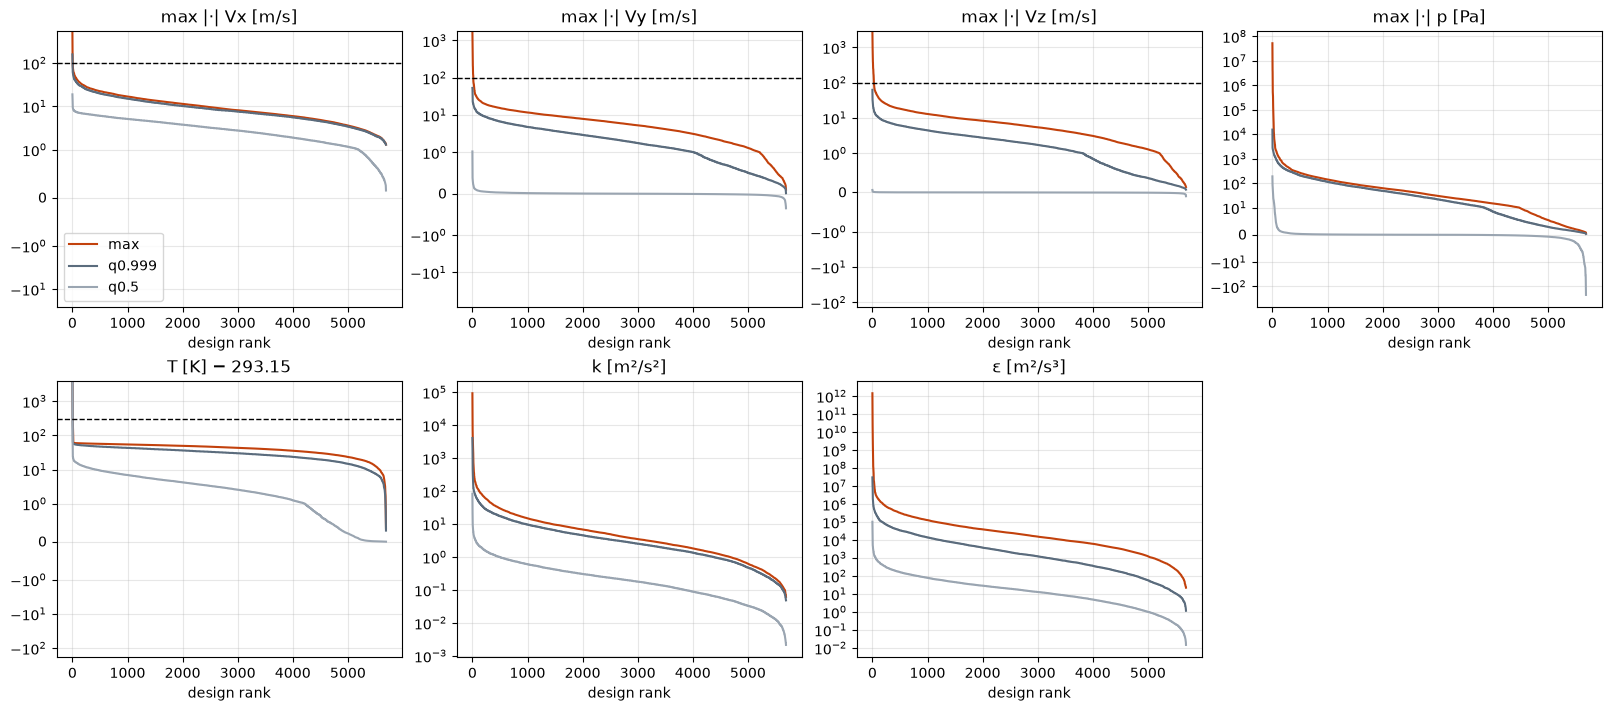

In [2]:
SIGNED_CHANNELS = CHANNELS[:4]  # velocities and p

figure, axes = plt.subplots(2, 4, figsize=(16, 7), layout="constrained")
for axis, channel in zip(axes.flat, CHANNELS, strict=False):
    per_design = design_stats.filter(pl.col("channel") == channel.value)
    offset = sweep.BINNING[channel][0]
    extreme = pl.max_horizontal(pl.col("max"), -pl.col("min")) if channel in SIGNED_CHANNELS else pl.col("max")
    for label, column, color in (("max", extreme, "#c2410c"), ("q0.999", pl.col("q0.999"), "#5b6c7d"), ("q0.5", pl.col("q0.5"), "#9aa5b1")):
        values = np.sort(per_design.select(column).to_series().to_numpy())[::-1]
        axis.plot(values - offset, color=color, label=label)
    if channel in CHANNELS[:3]:
        axis.axhline(sweep.MAX_VELOCITY, color="black", linestyle="--", linewidth=1)
    if channel is Channel.TEMPERATURE:
        axis.axhline(sweep.TEMPERATURE_RANGE[1] - offset, color="black", linestyle="--", linewidth=1)
    axis.set_yscale("symlog", linthresh=sweep.BINNING[channel][1] * 100)
    prefix = "max |·| " if channel in SIGNED_CHANNELS else ""
    axis.set_title(prefix + channel.value + (f" − {offset:g}" if offset else ""))
    axis.set_xlabel("design rank")
    axis.grid(alpha=0.3)
axes.flat[0].legend()
axes.flat[-1].axis("off")
plt.show()

## Outlier designs

Excluded by the sweep's outlier rule (`MAX_VELOCITY`, `TEMPERATURE_RANGE` in `value_distribution.py`), read from `excluded_designs.csv`. `T median` separates whole-design failures (median far above 293 K) from local ones. T min below 250 K is not visible in the ranking plot, which shows maxima only.

In [3]:
wide = design_stats.pivot(on="channel", index="design_id", values=["min", "max", "q0.5"])
velocity_extreme = pl.max_horizontal([pl.col(f"{bound}_{c.value}").abs() for c in CHANNELS[:3] for bound in ("min", "max")])
outliers = (
    excluded.join(wide.with_columns(velocity_extreme=velocity_extreme), on="design_id")
    .sort("velocity_extreme", descending=True)
)
is_outlier = np.isin(design_id, outliers["design_id"].to_numpy())
print(f"{is_outlier.sum()} of {len(design_id)} designs excluded")
with pl.Config(fmt_str_lengths=80):
    display(outliers.select("design_id", "reason", pl.col("q0.5_T [K]").alias("T median"), pl.col("max_p [Pa]")))  # noqa: F821

26 of 5692 designs excluded


design_id,reason,T median,max_p [Pa]
i64,str,f64,f64
243826,"""|V| 2811 > 100 m/s, T min 214 < 250 K, T max 4068 > 600 K""",3861.7275,51812504.0000
128001,"""|V| 1682 > 100 m/s, T min 139 < 250 K, T max 4015 > 600 K""",3774.1020,11388496.0000
245751,"""|V| 1255 > 100 m/s, T max 2386 > 600 K""",2233.8850,4145907.2500
34855,"""|V| 931 > 100 m/s, T max 1434 > 600 K""",307.8168,3456479.7500
6092,"""|V| 908 > 100 m/s, T max 3491 > 600 K""",297.8238,5653156.5000
17453,"""|V| 707 > 100 m/s, T max 683 > 600 K""",349.3039,1090111.8750
217042,"""|V| 483 > 100 m/s""",366.0537,388461.7812
187314,"""|V| 474 > 100 m/s, T max 674 > 600 K""",300.8344,961500.6250
174805,"""|V| 453 > 100 m/s, T max 605 > 600 K""",487.7912,522340.5625


## Outlier slices

Every flagged design, most extreme velocity first. Top view at the height of its fastest voxel (white cross), solids grey. Log color scales, so both the bulk and the extremes stay visible. Shown at 400x80x16, the statistics come from the sweep grid.

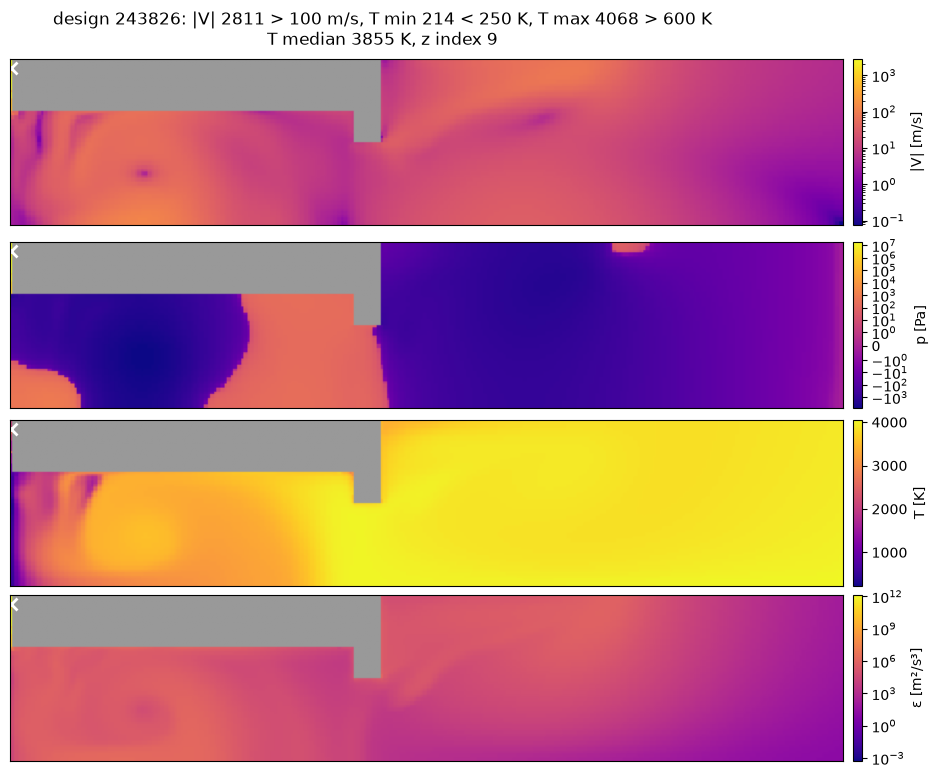

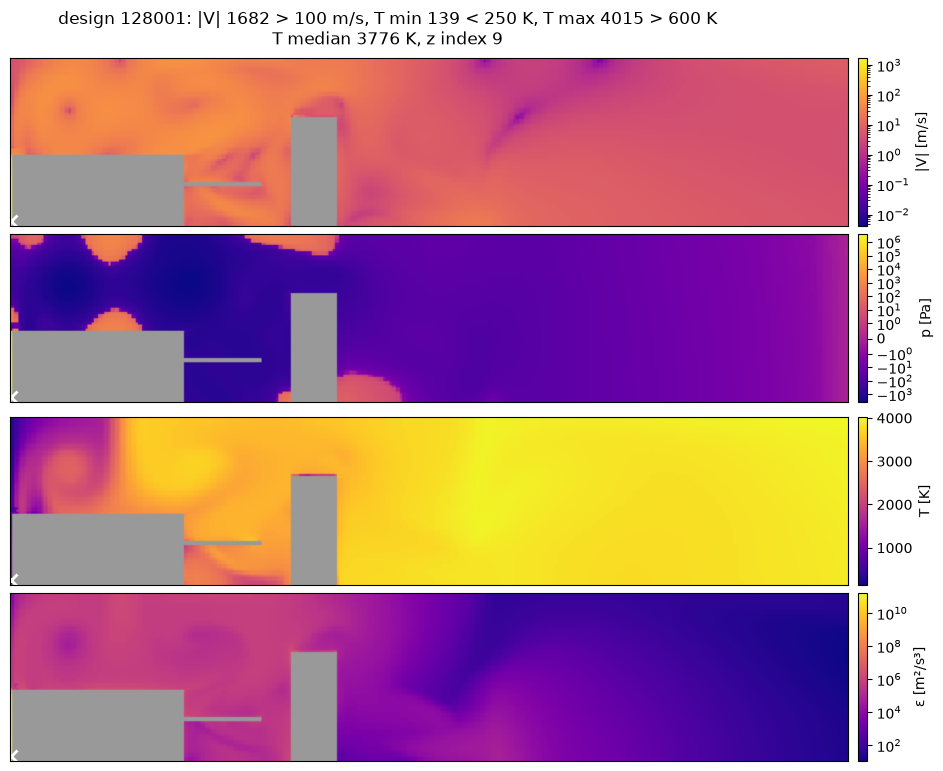

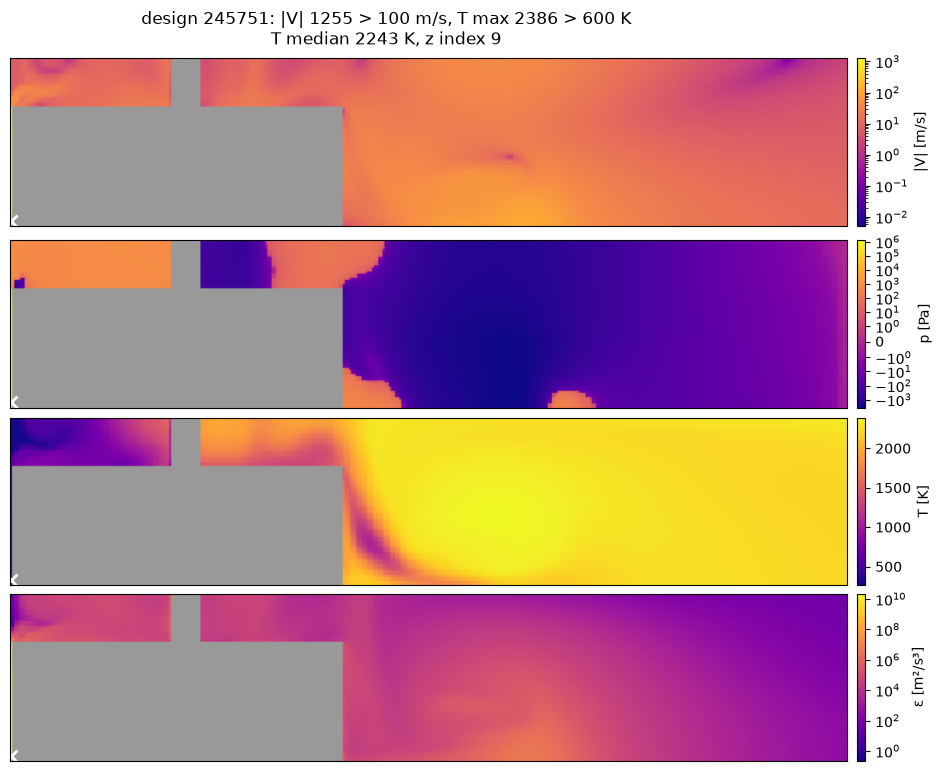

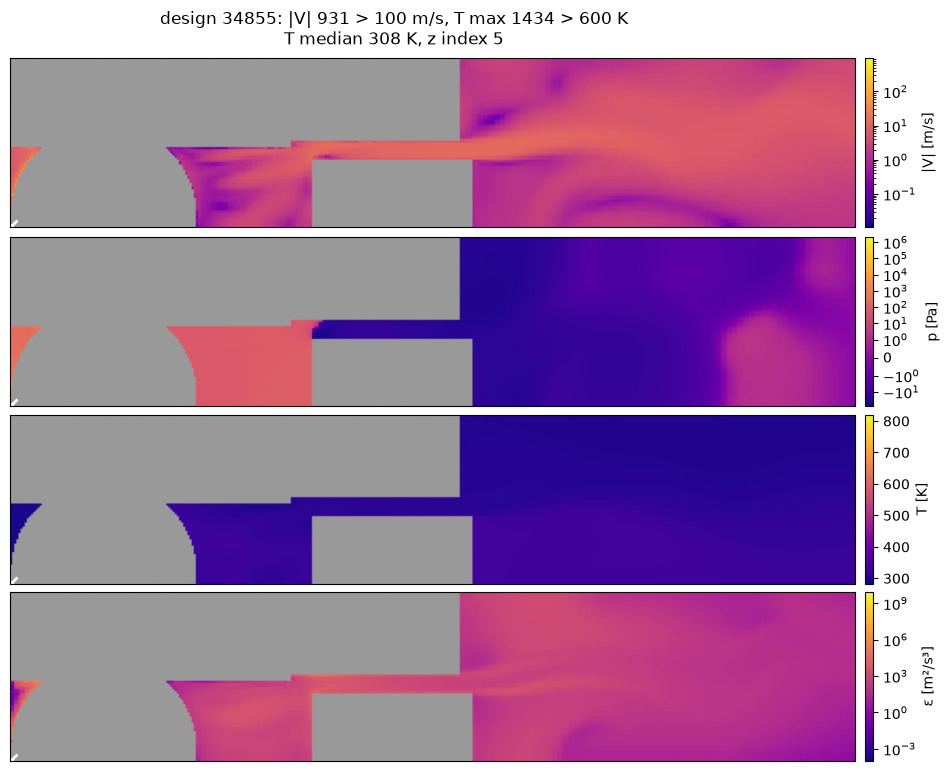

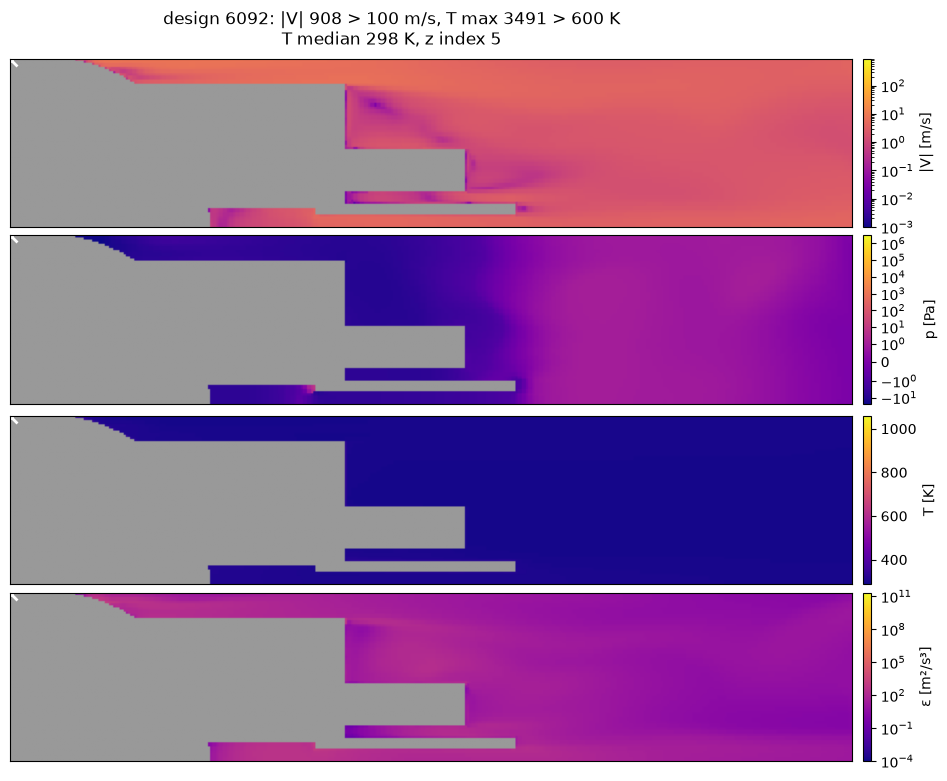

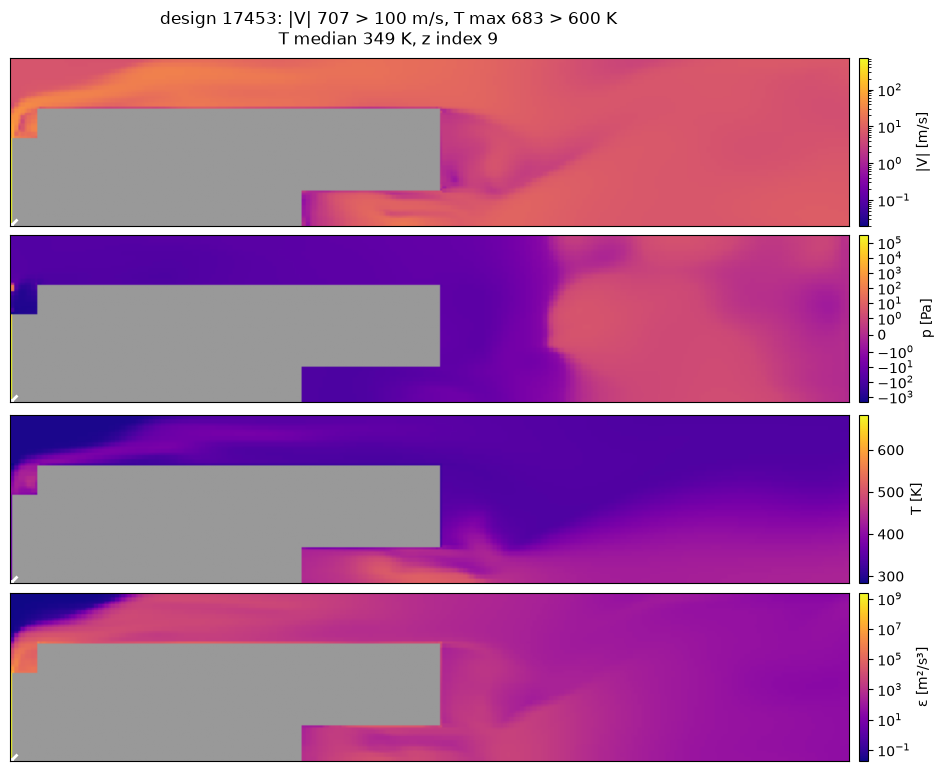

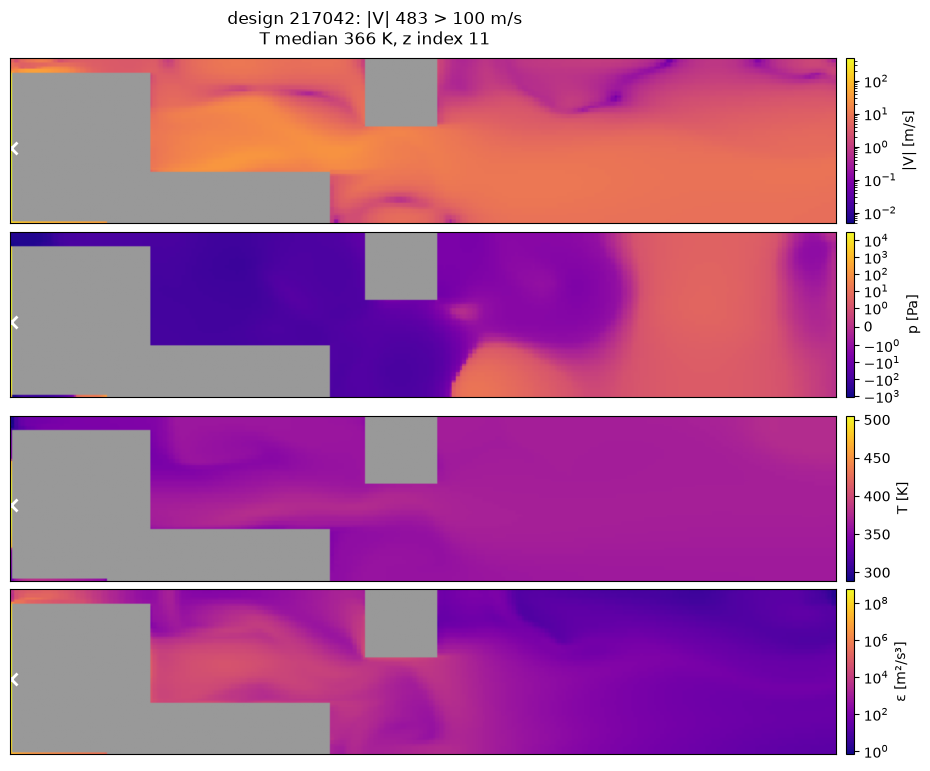

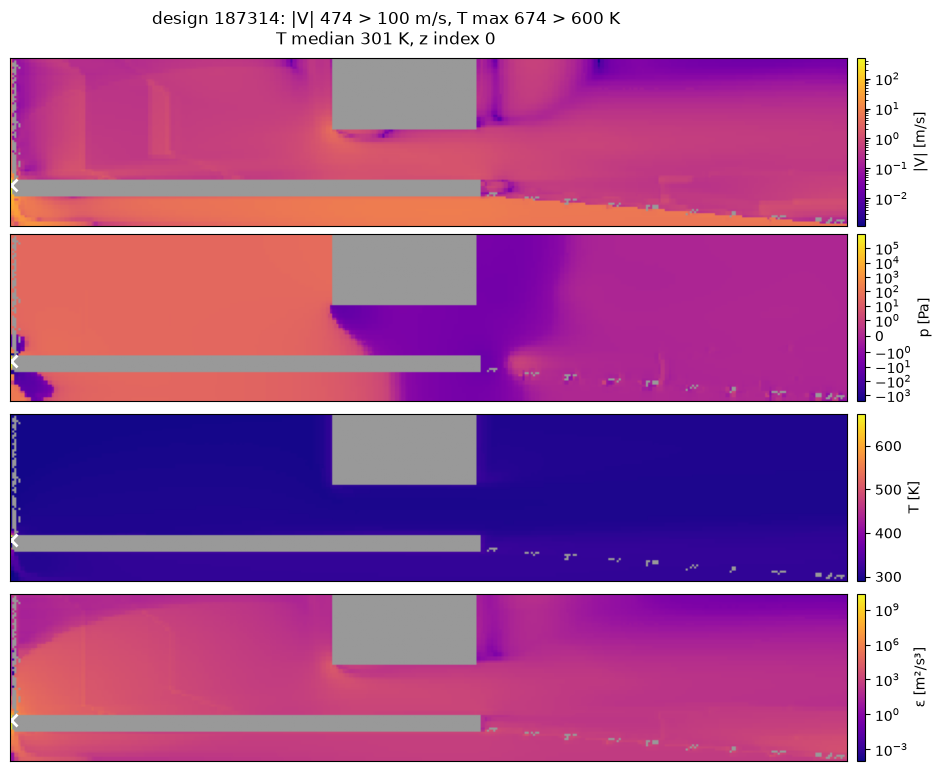

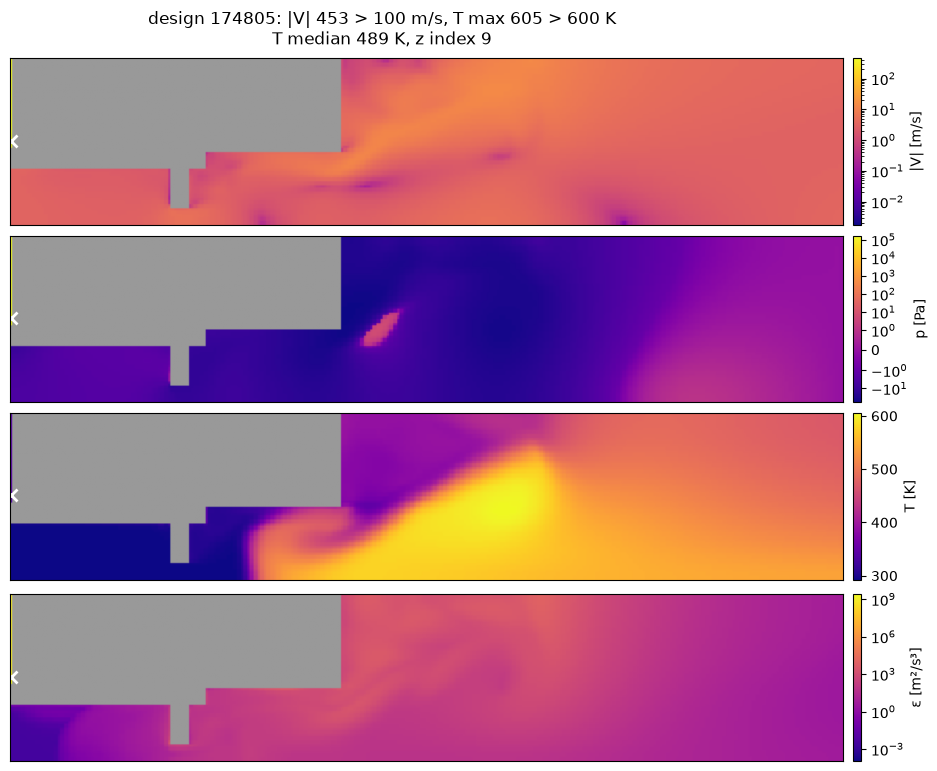

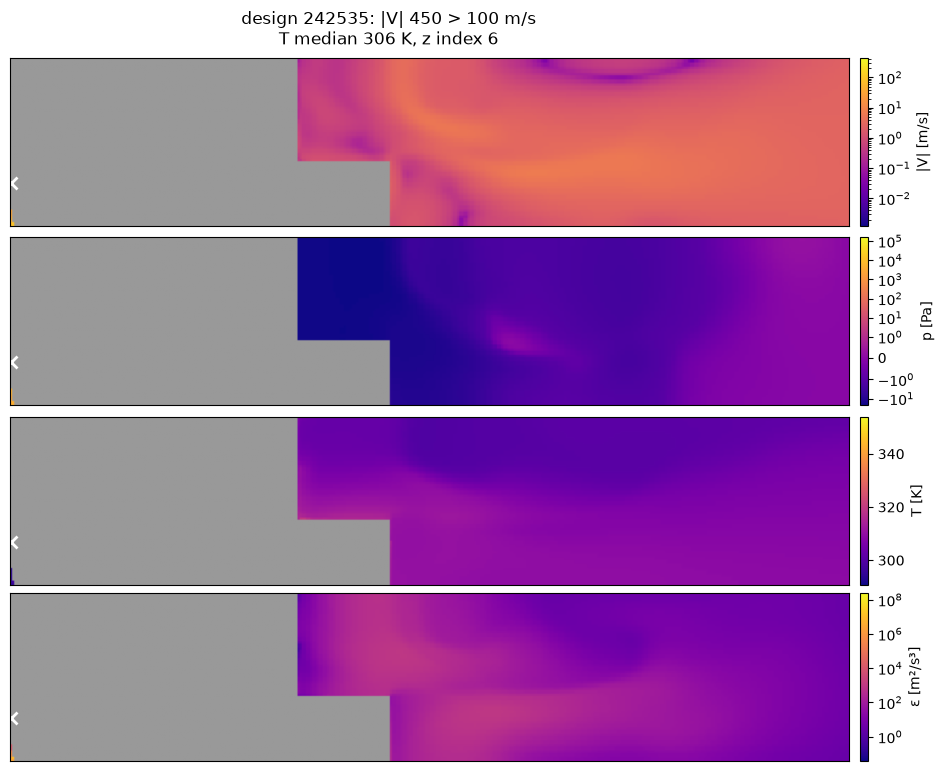

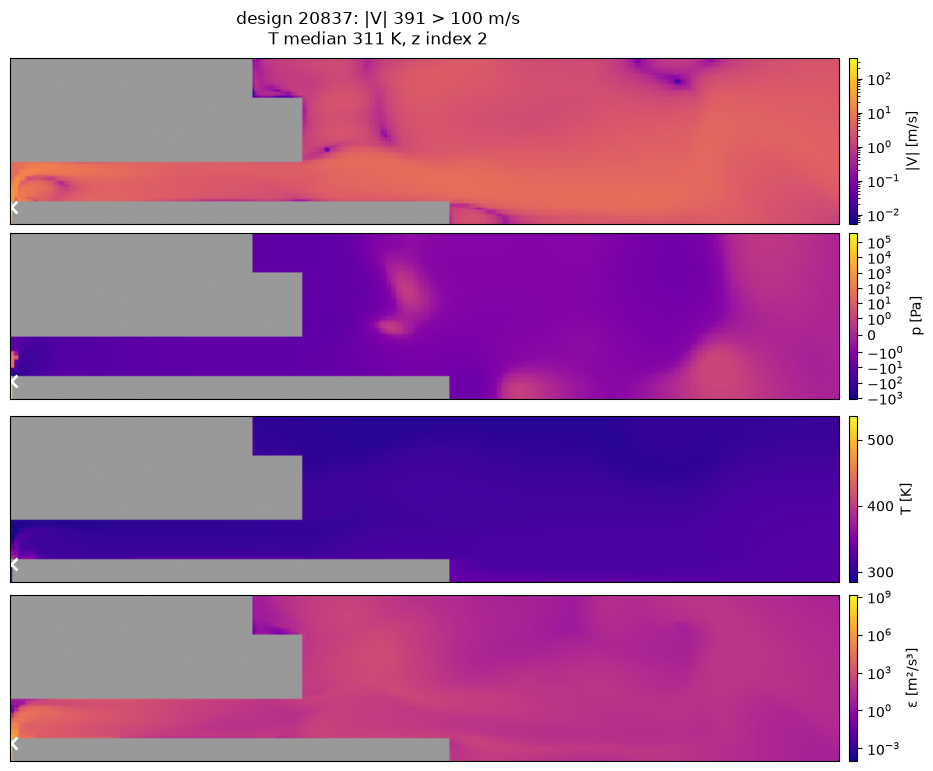

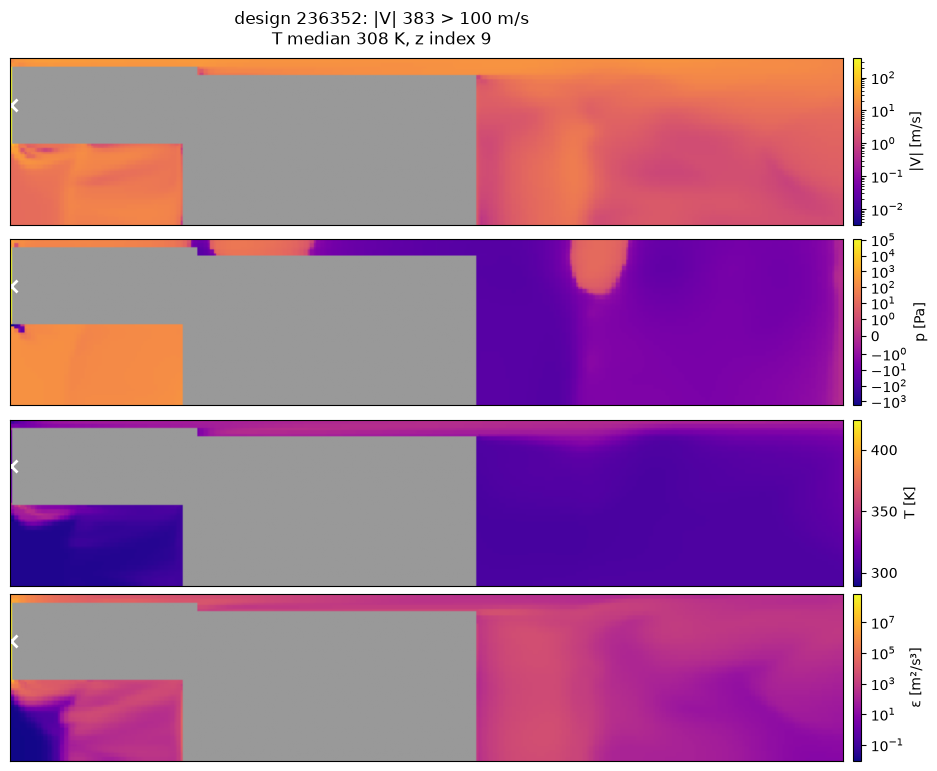

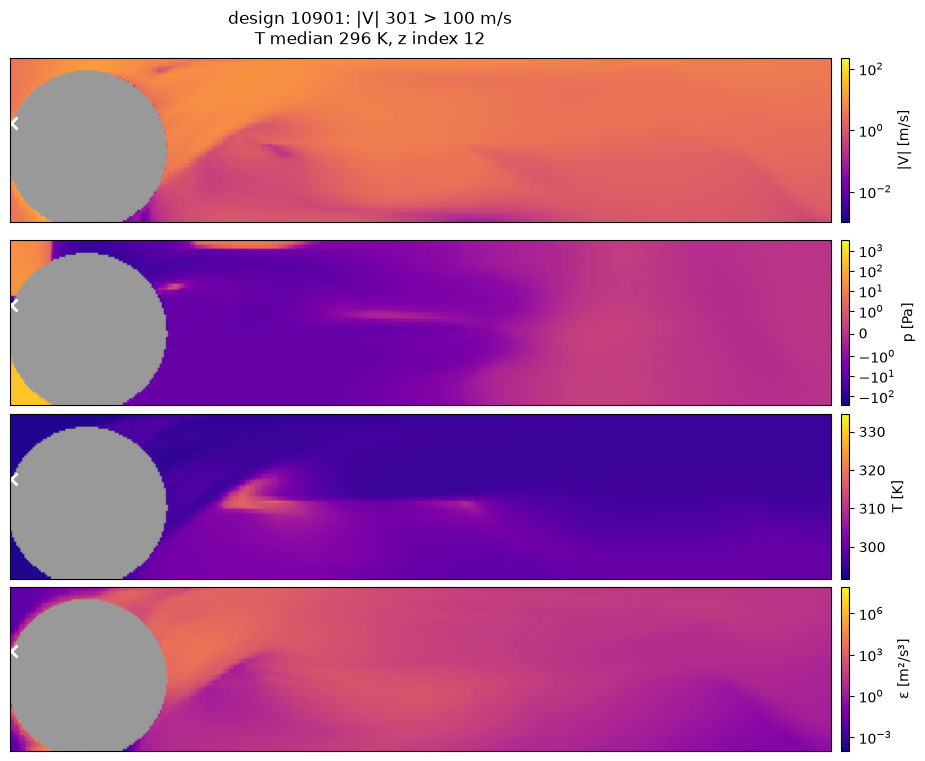

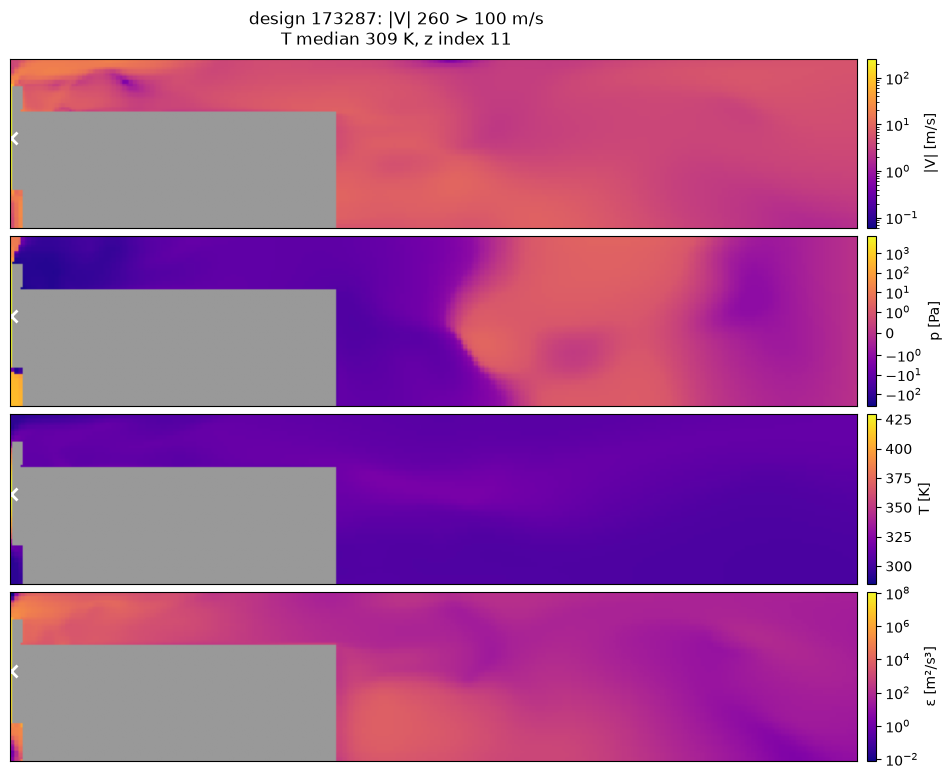

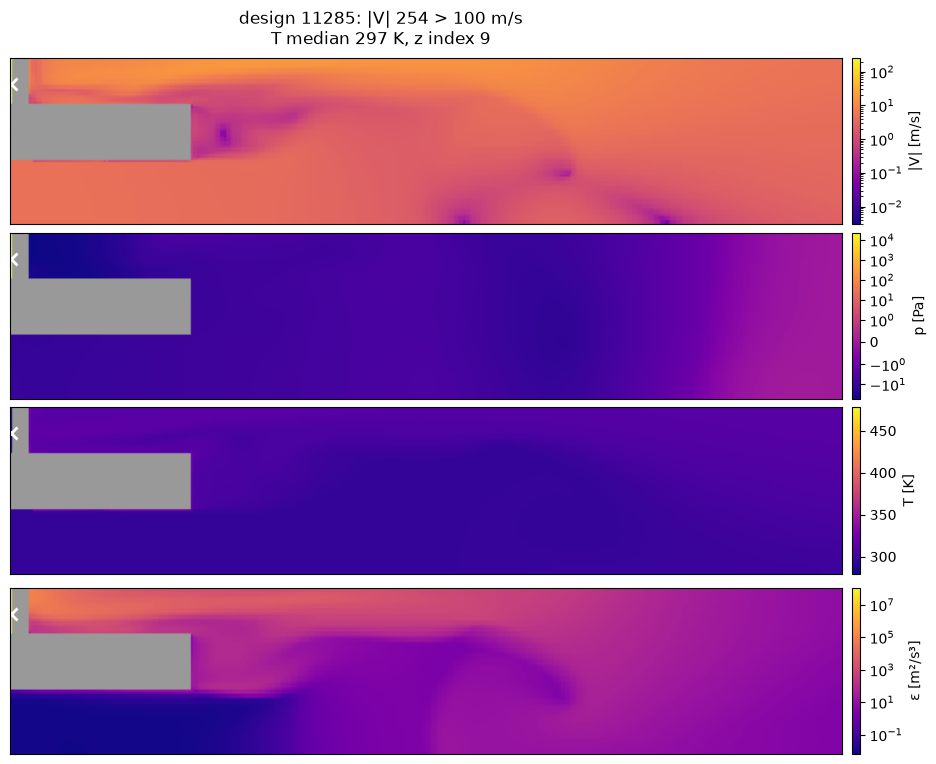

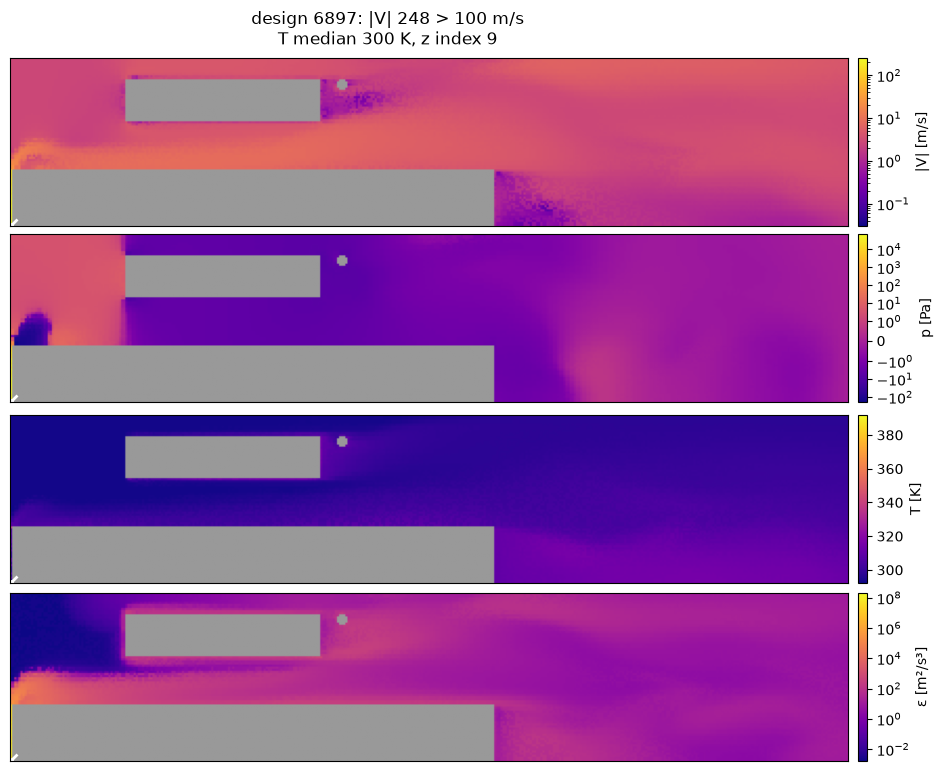

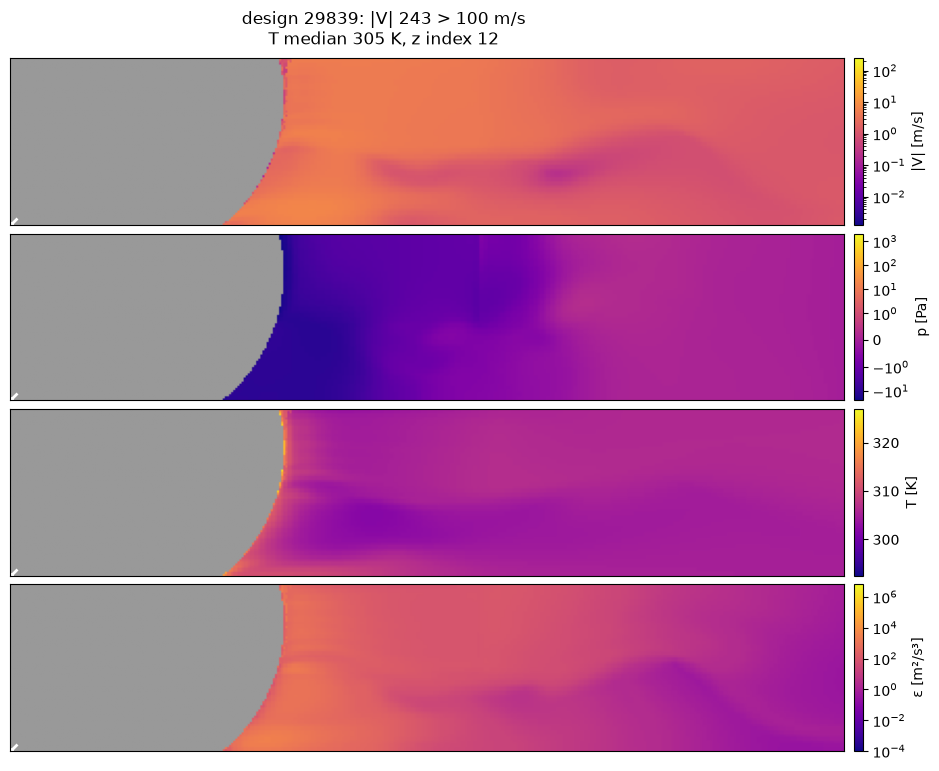

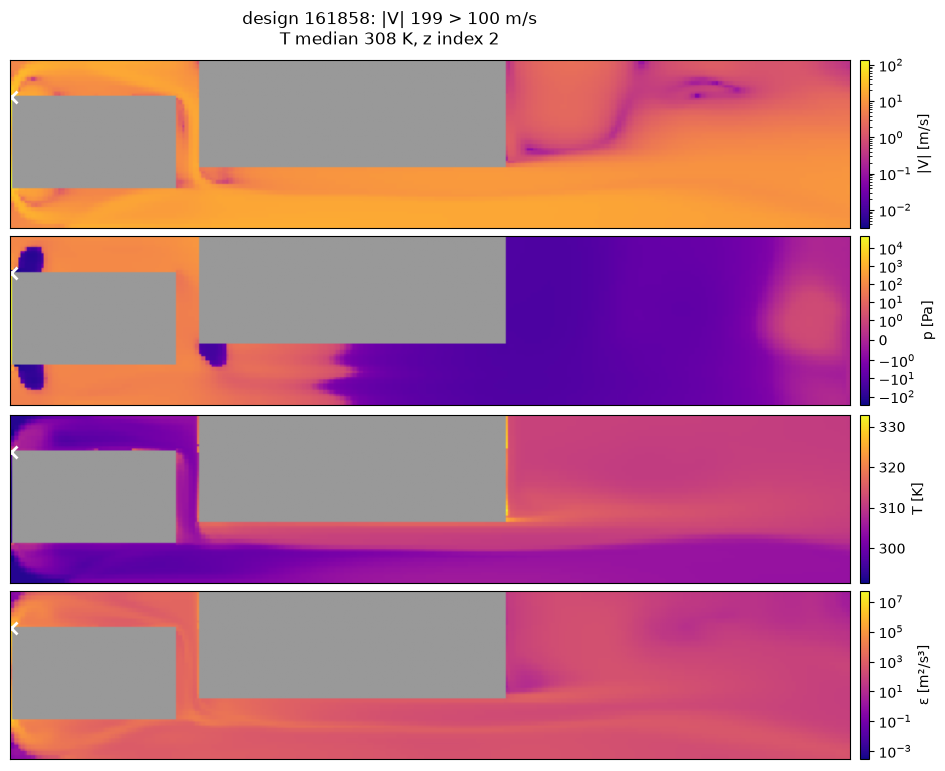

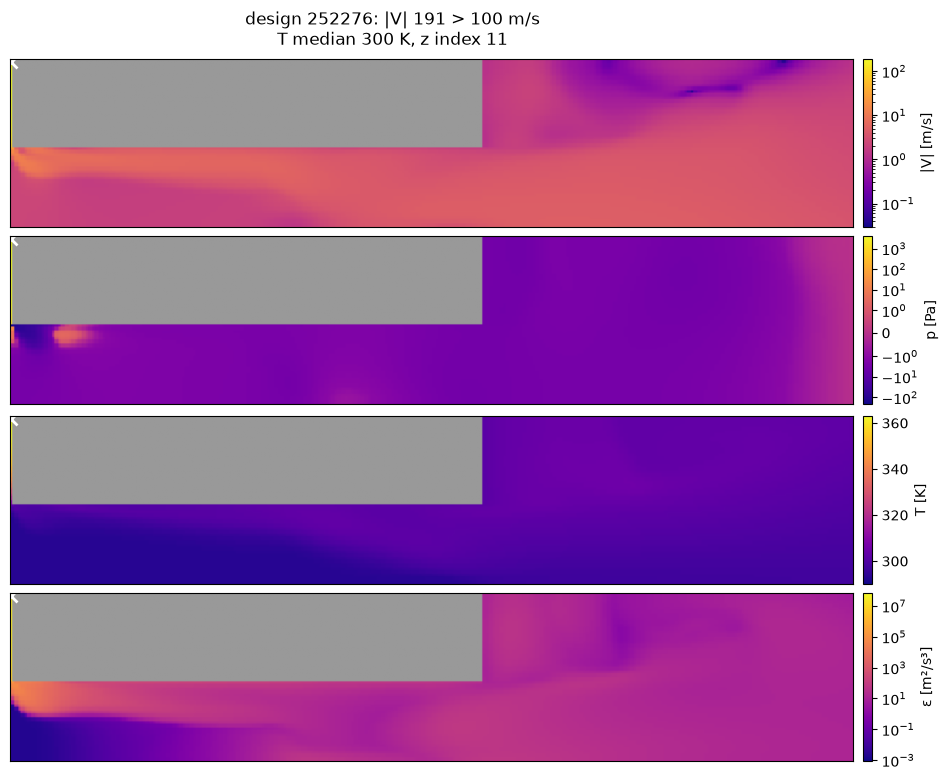

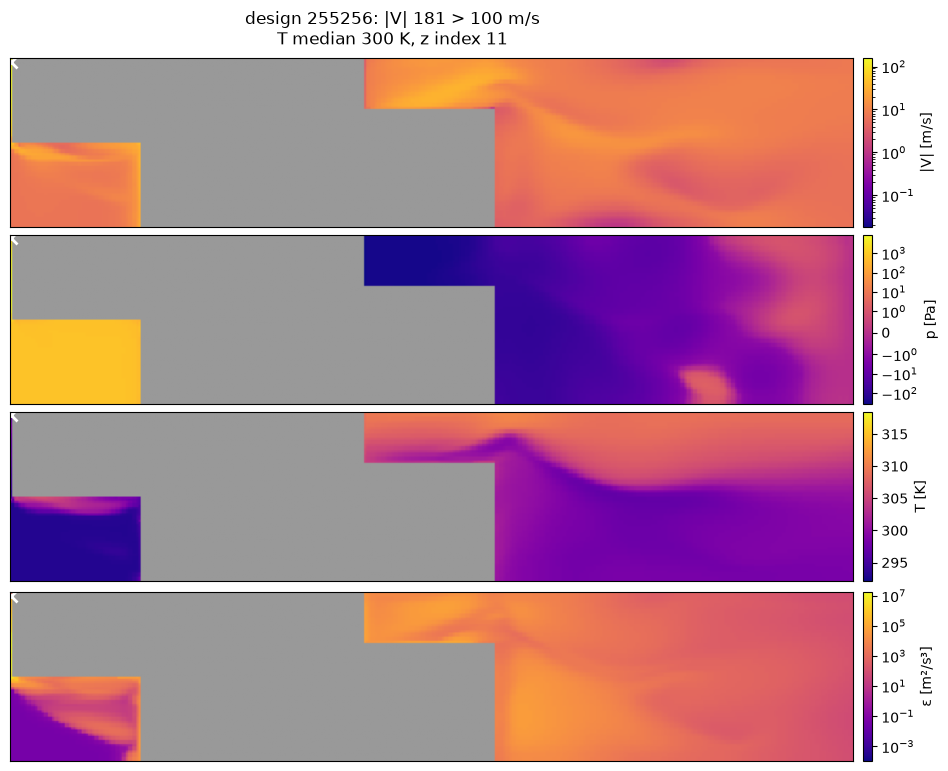

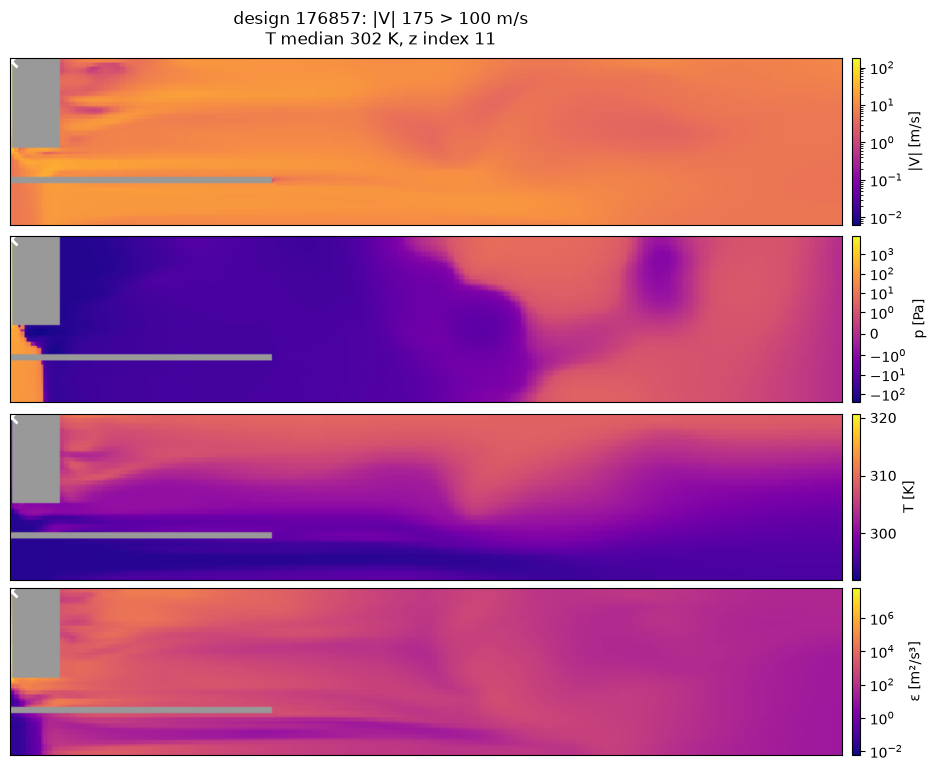

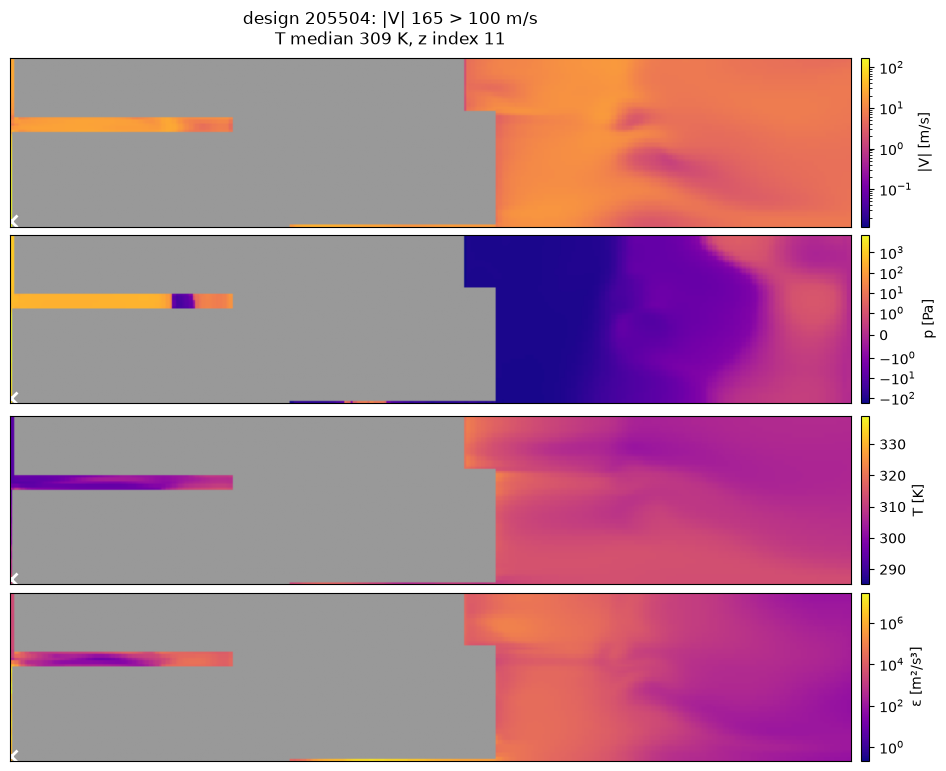

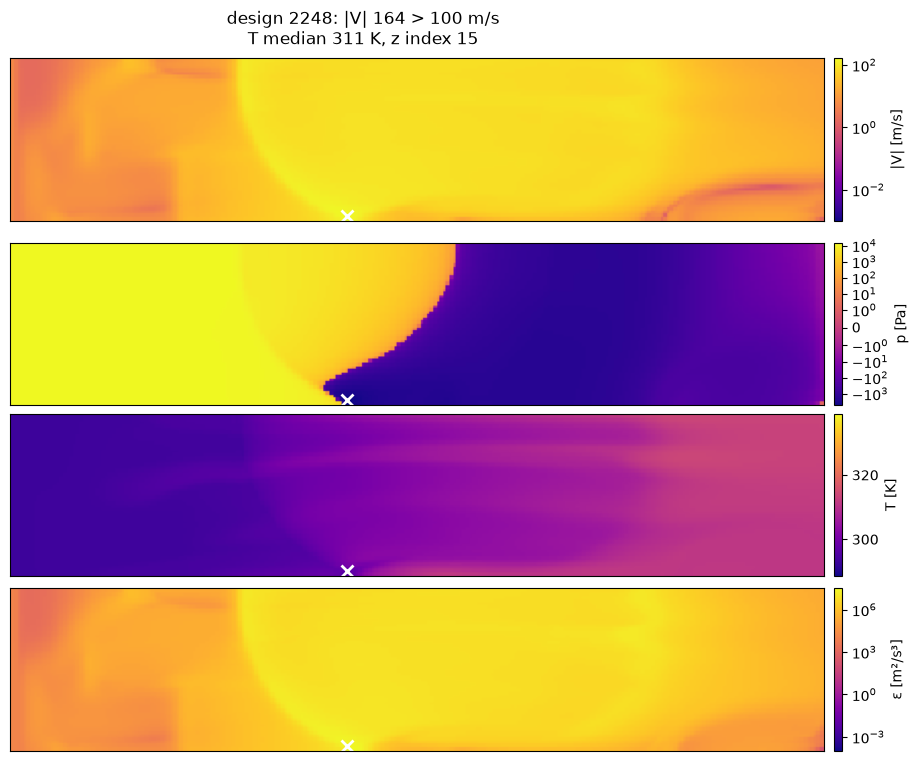

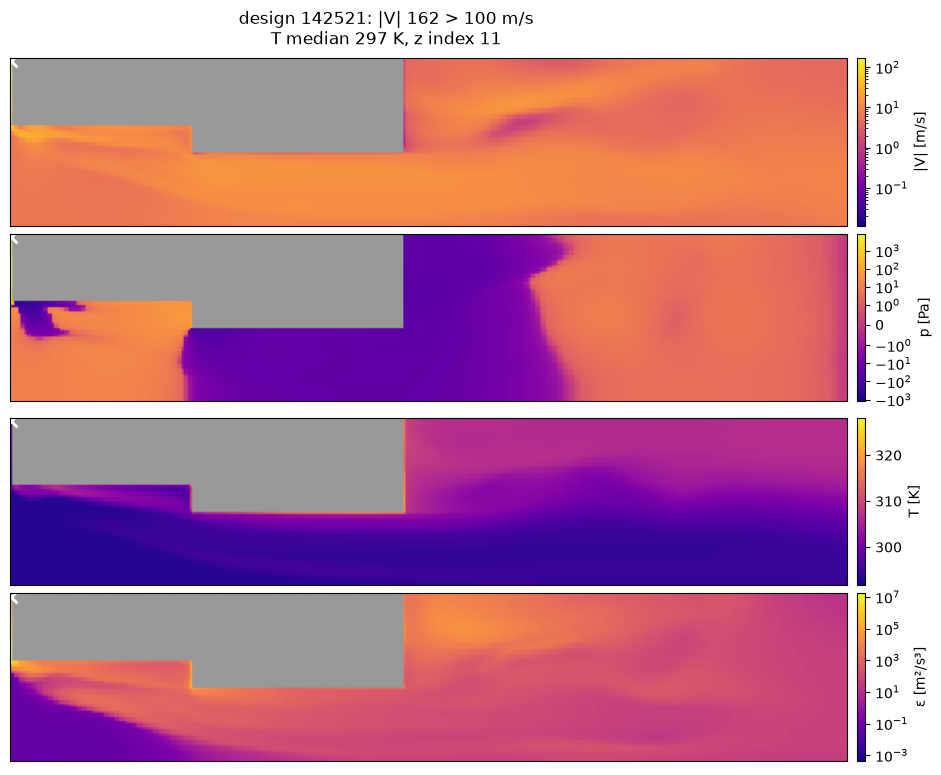

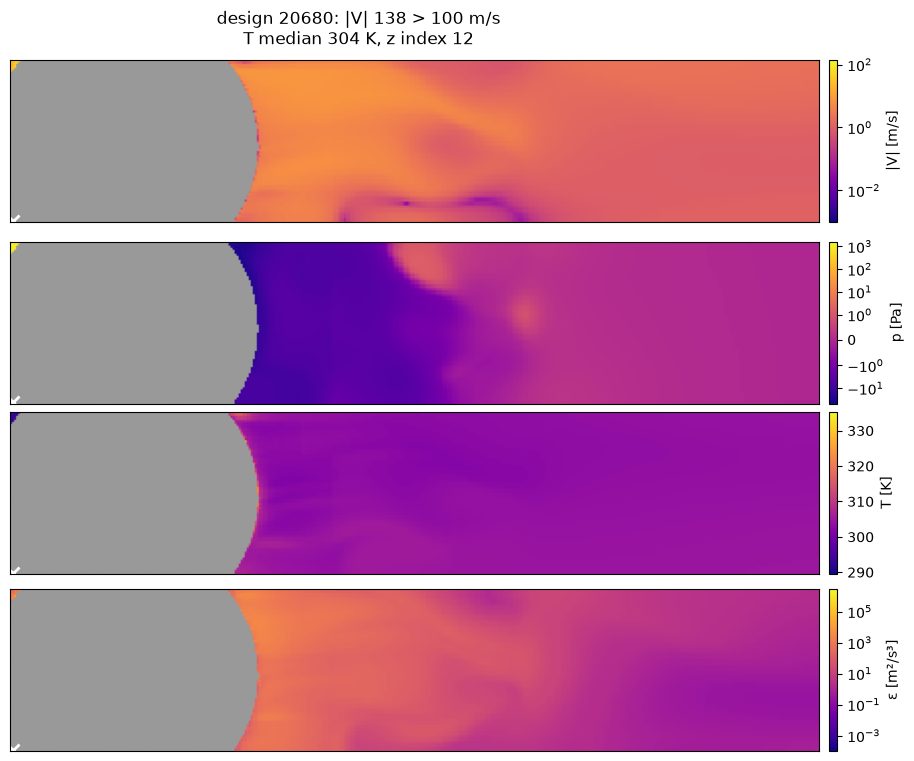

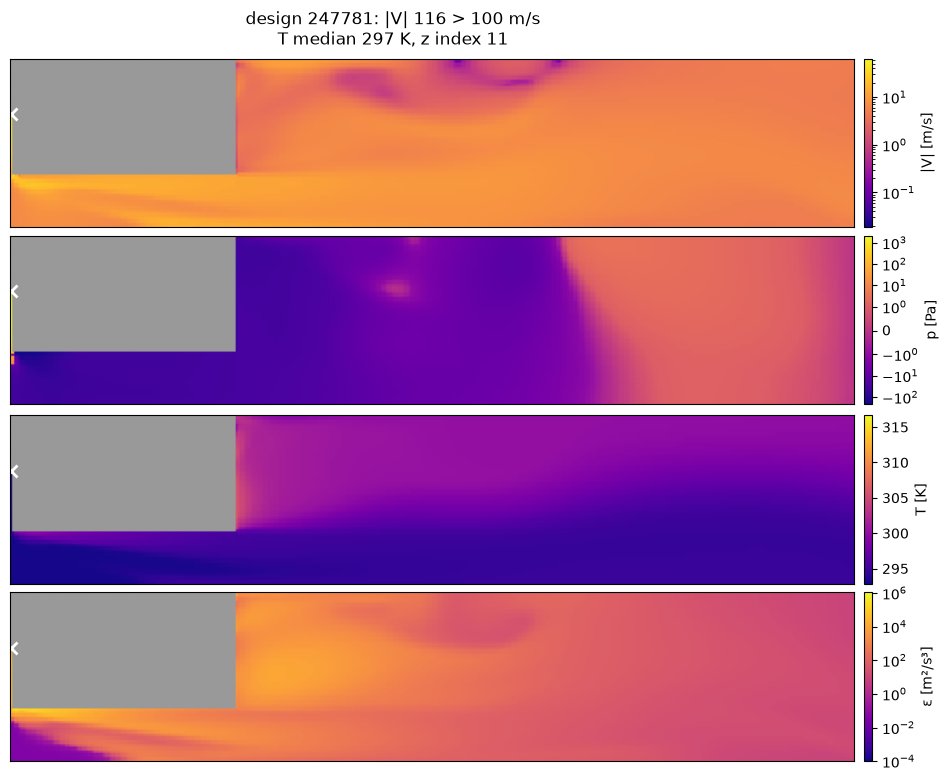

In [4]:
from matplotlib.colors import LogNorm, Normalize, SymLogNorm  # noqa: E402

from coolfrog.engine.cooldata import CoolData, CoolMetadata  # noqa: E402
from coolfrog.lib.config import HOST_CONFIG  # noqa: E402

from coolfrog.lib.config import DataConfig  # noqa: E402
from coolfrog.lib.datatypes import Grid  # noqa: E402

GRID = Grid(latent_scale=1)  # views only, 33M voxels per design at the sweep grid are too heavy to render
dataset = CoolData(CoolMetadata.load(HOST_CONFIG.n_splits, HOST_CONFIG.idx_split), DataConfig(grid=GRID))
index_of_design = {design: index for index, design in enumerate(dataset.design_ids)}
extent_mm = (0.0, 1000 * GRID.extent[0], 0.0, 1000 * GRID.extent[1])


def plot_outlier(design: int, reason: str) -> None:
    """Top-view slices of |V|, p, T and ε through the fastest fluid voxel of `design`."""
    flowfield = dataset[index_of_design[design]]
    fields, fluid = flowfield.fields.numpy(), flowfield.mask.numpy()
    speed = np.linalg.norm(fields[:3], axis=0)
    x, y, z = np.unravel_index(np.argmax(np.where(fluid, speed, 0)), speed.shape)
    temperature, dissipation = fields[CHANNELS.index(Channel.TEMPERATURE)], fields[CHANNELS.index(Channel.TURBULENT_DISSIPATION_RATE)]
    panels = (
        ("|V| [m/s]", speed, LogNorm(vmin=max(speed[fluid].min(), 1e-3), vmax=speed[fluid].max())),
        ("p [Pa]", fields[CHANNELS.index(Channel.PRESSURE)], SymLogNorm(linthresh=1)),
        ("T [K]", temperature, Normalize(temperature[fluid].min(), temperature[fluid].max())),
        ("ε [m²/s³]", dissipation, LogNorm(vmin=max(dissipation[fluid].min(), 1e-4), vmax=dissipation[fluid].max())),
    )
    figure, axes = plt.subplots(len(panels), 1, figsize=(11, 1.9 * len(panels)), layout="constrained")
    for axis, (label, volume, norm) in zip(axes, panels, strict=True):
        image = axis.imshow(
            np.where(fluid, volume, np.nan)[:, :, z].T,
            origin="lower",
            extent=extent_mm,
            norm=norm,
            cmap=plt.colormaps["plasma"].with_extremes(bad=SOLID_COLOR),
        )
        axis.plot(*((np.array([x, y]) + 0.5) / np.array(GRID.shape[:2]) * np.array(extent_mm[1::2])), "x", color="white", markersize=9, mew=2)
        axis.set_xticks([])
        axis.set_yticks([])
        figure.colorbar(image, ax=axis, fraction=0.02, pad=0.01, label=label)
    figure.suptitle(f"design {design}: {reason}\nT median {np.median(temperature[fluid]):.0f} K, z index {z}")
    plt.show()


for design, reason in outliers.select("design_id", "reason").iter_rows():
    plot_outlier(design, reason)

## Outlier volumes

3D view per flagged design: solids grey and translucent, coloured voxels break the rule (any velocity component > `MAX_VELOCITY` or T outside `TEMPERATURE_RANGE`), coloured by speed on a log scale. Whole-design failures fill the domain, local ones show where the extremes sit. `JUPYTER_BACKEND = "trame"` makes the views interactive in a running Jupyter server.

/tmp/ipykernel_892936/220409982.py:21: PyVistaFutureWarning: The default value of `algorithm` for the filter
`UnstructuredGrid.extract_surface` will change in the future. It currently defaults to
`'dataset_surface'`, but will change to `None`. Explicitly set the `algorithm` keyword to
silence this warning.
  plotter.add_mesh(image.threshold(0.5, scalars="solid").extract_surface(), color=SOLID_COLOR, opacity=0.3)


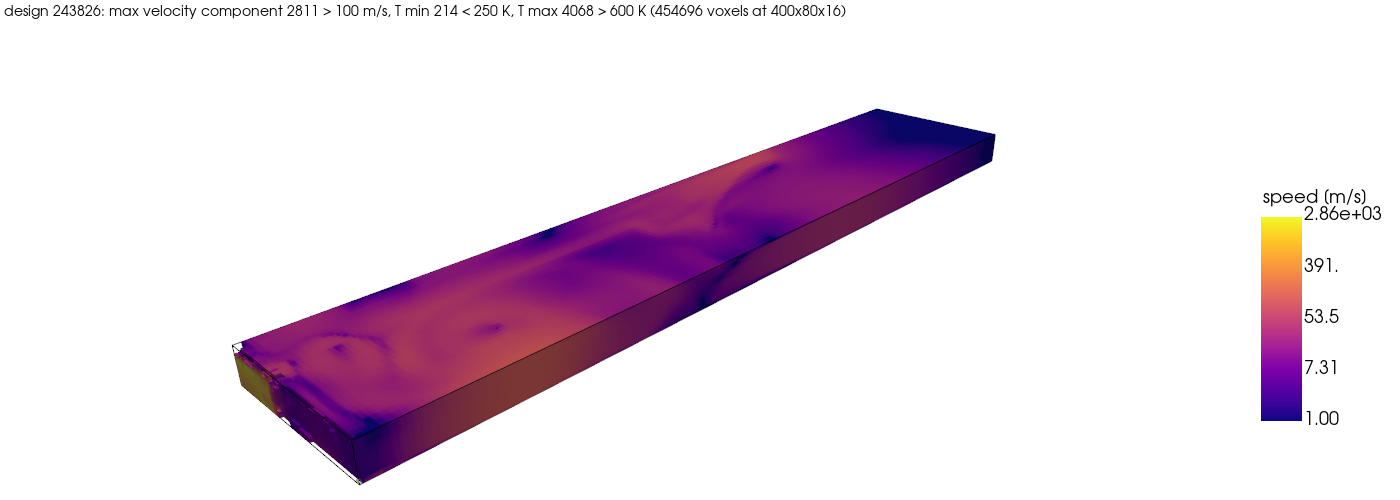

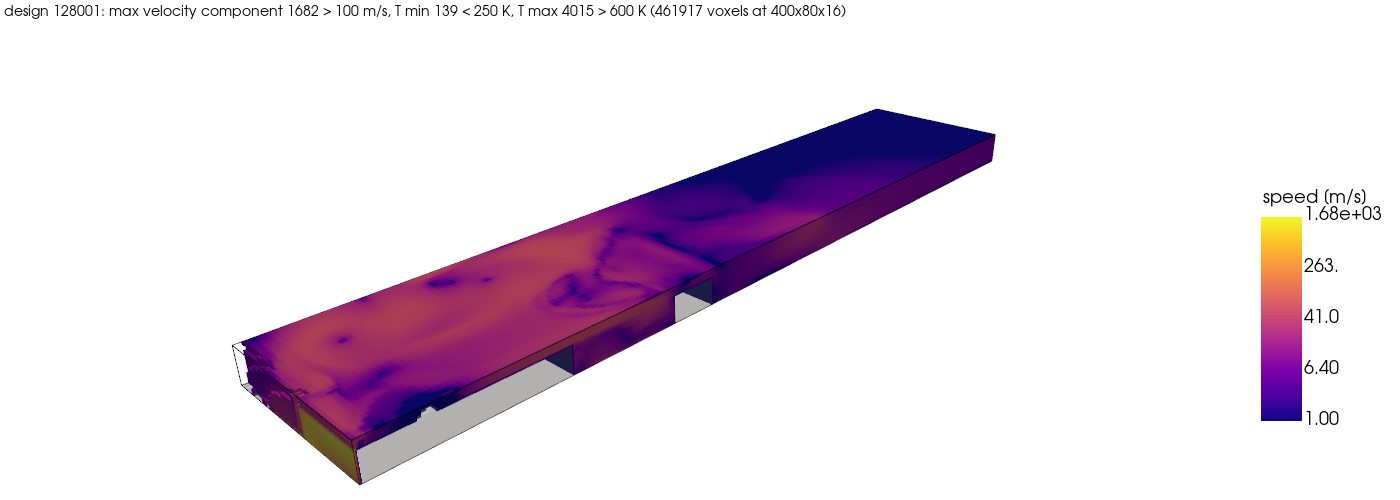

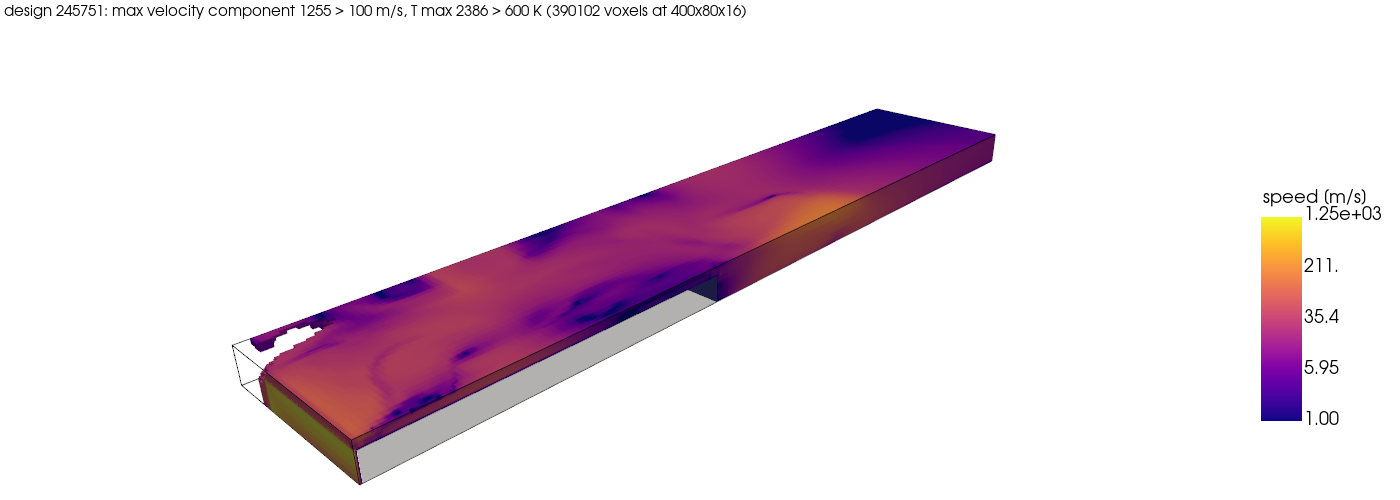

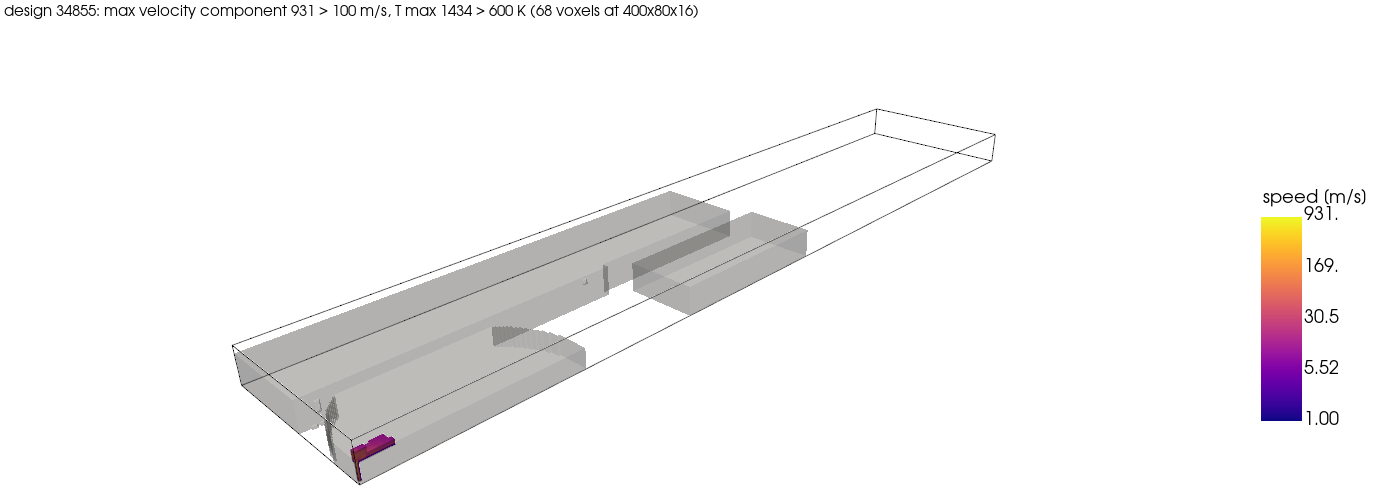

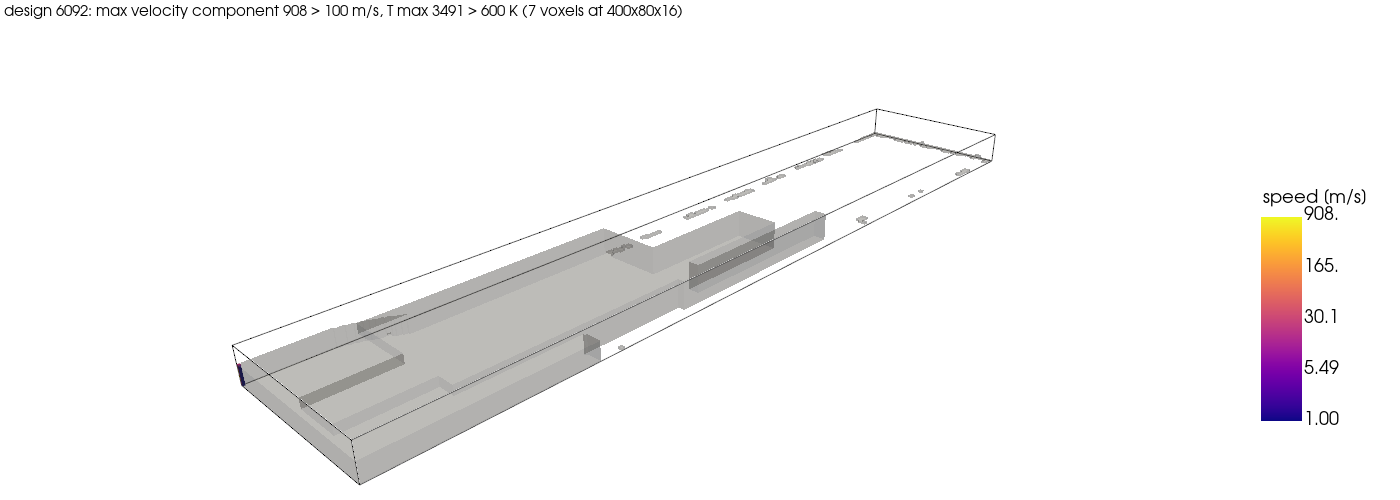

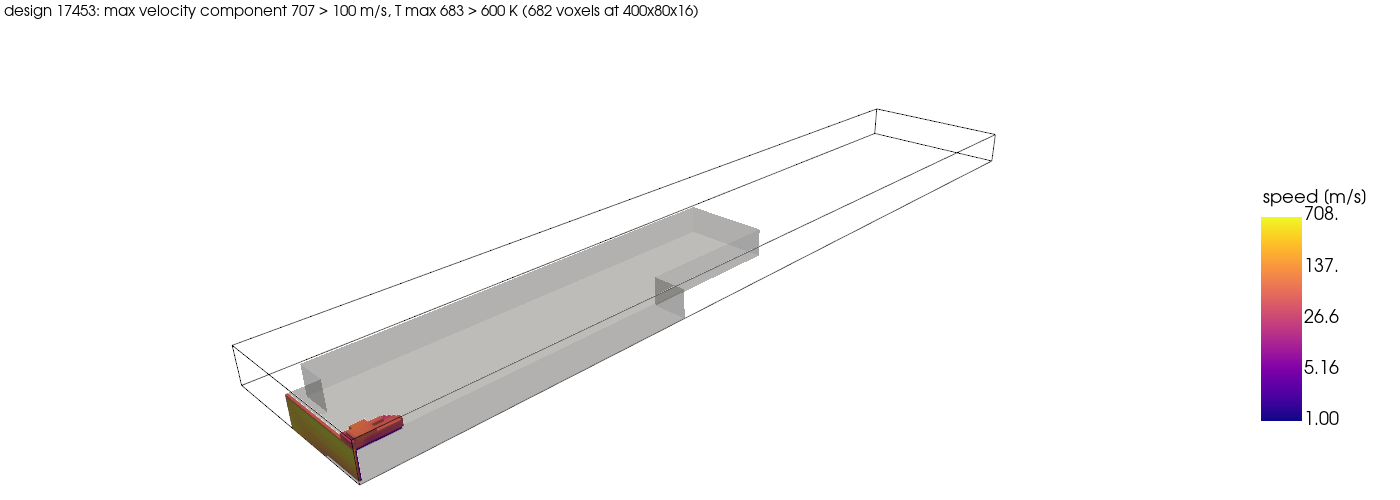

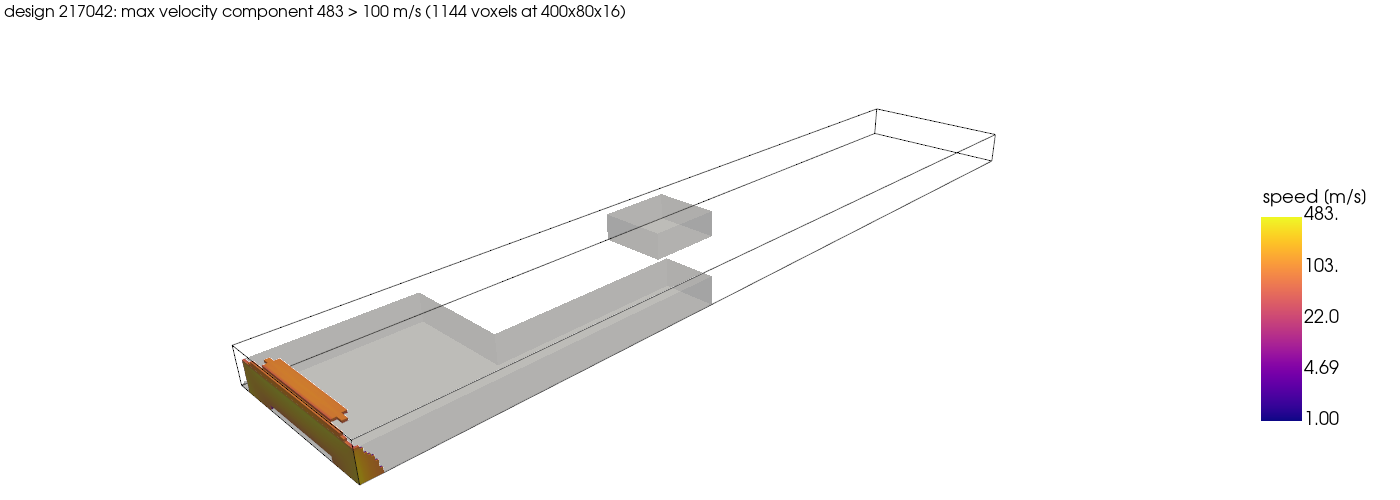

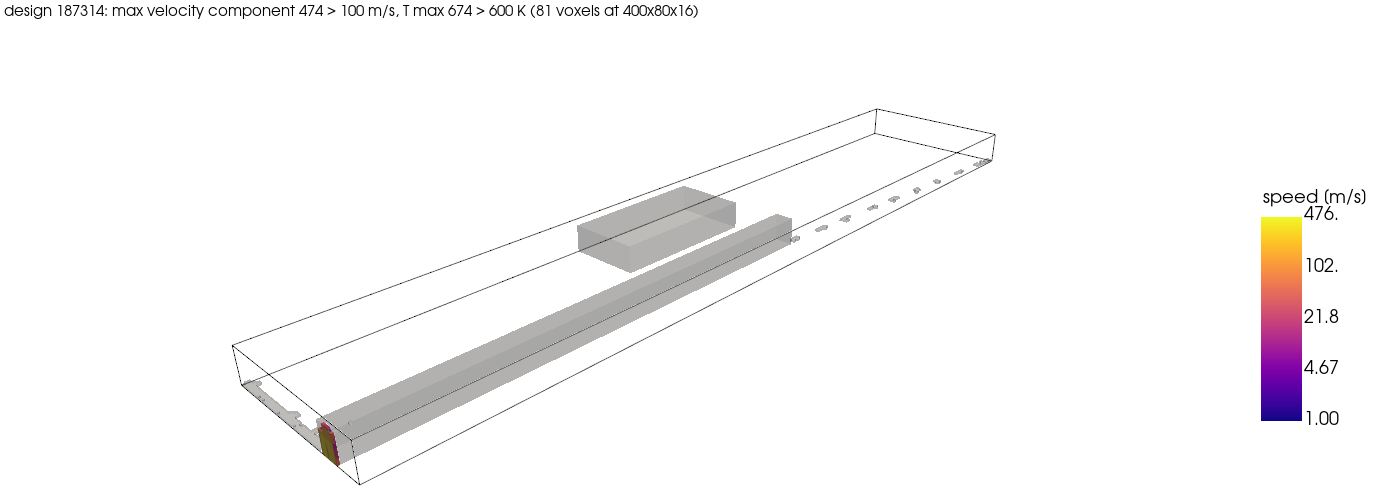

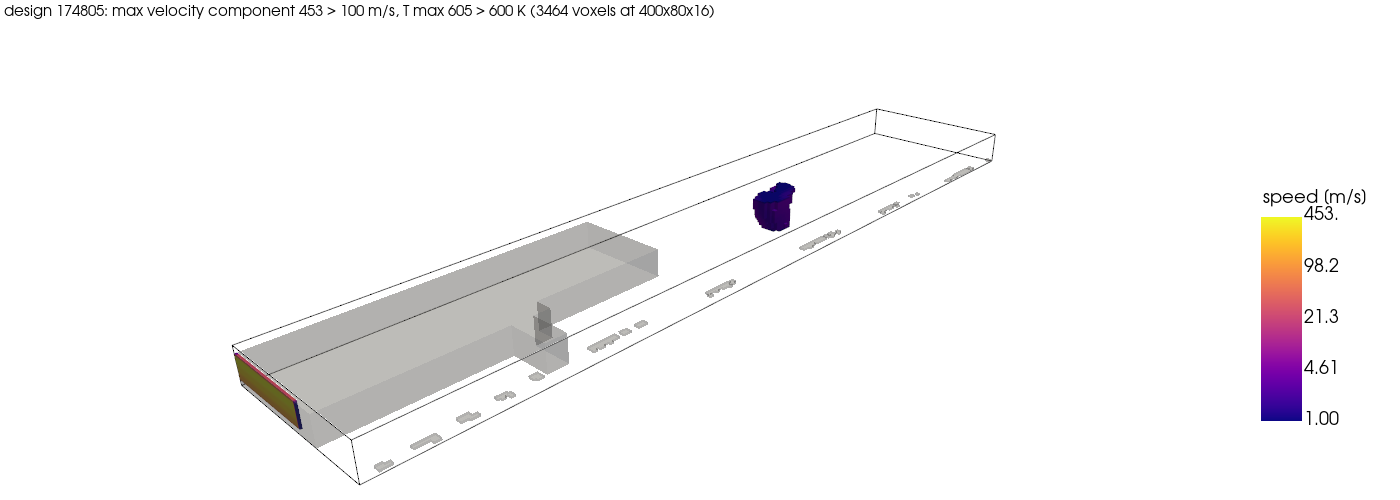

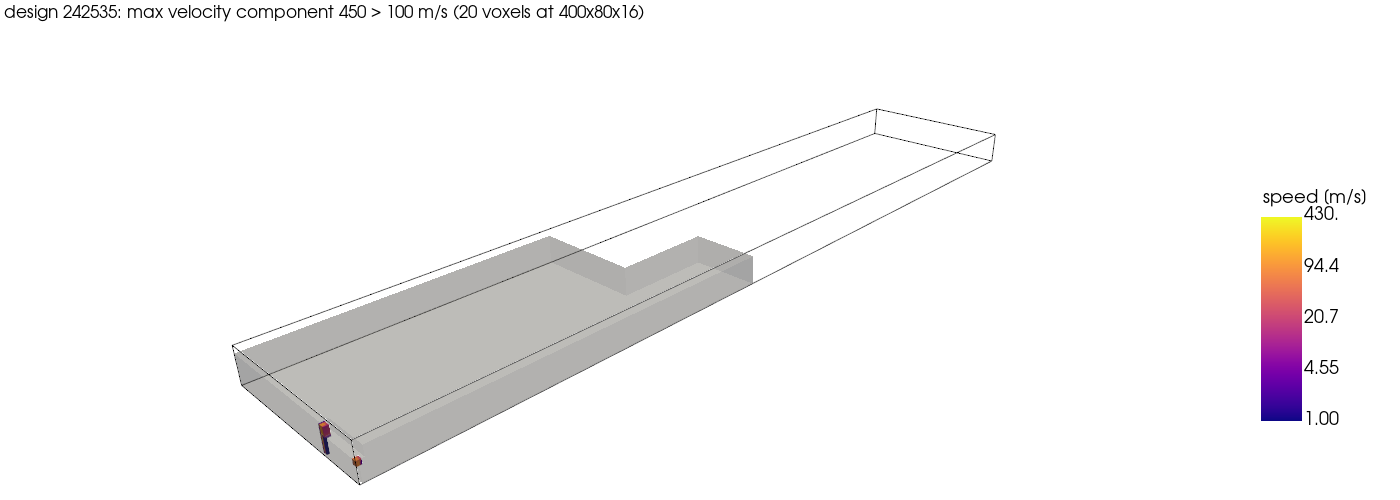

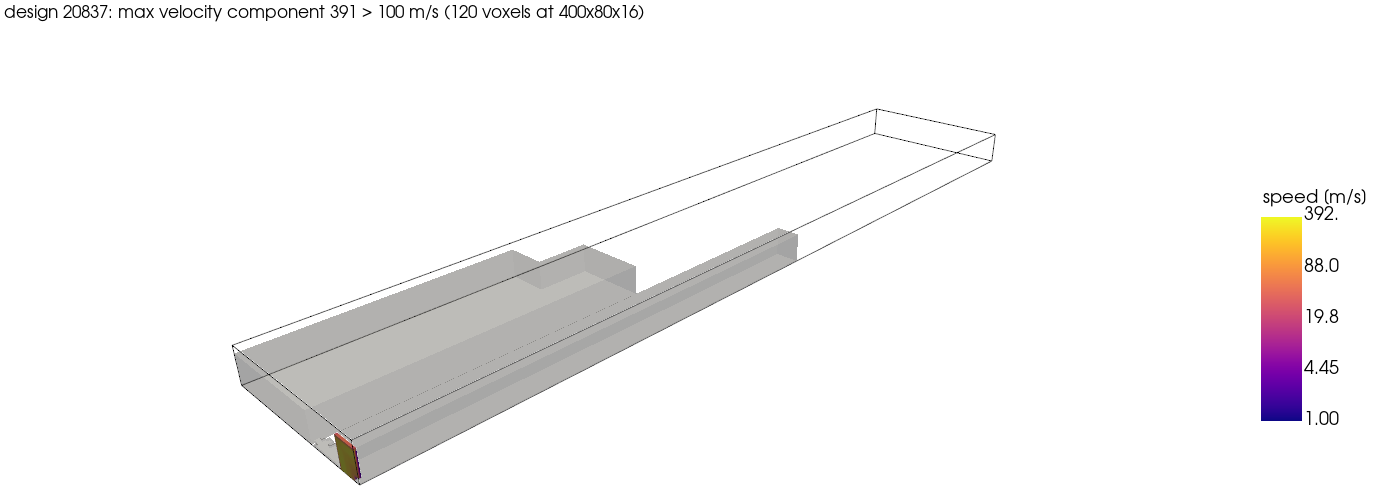

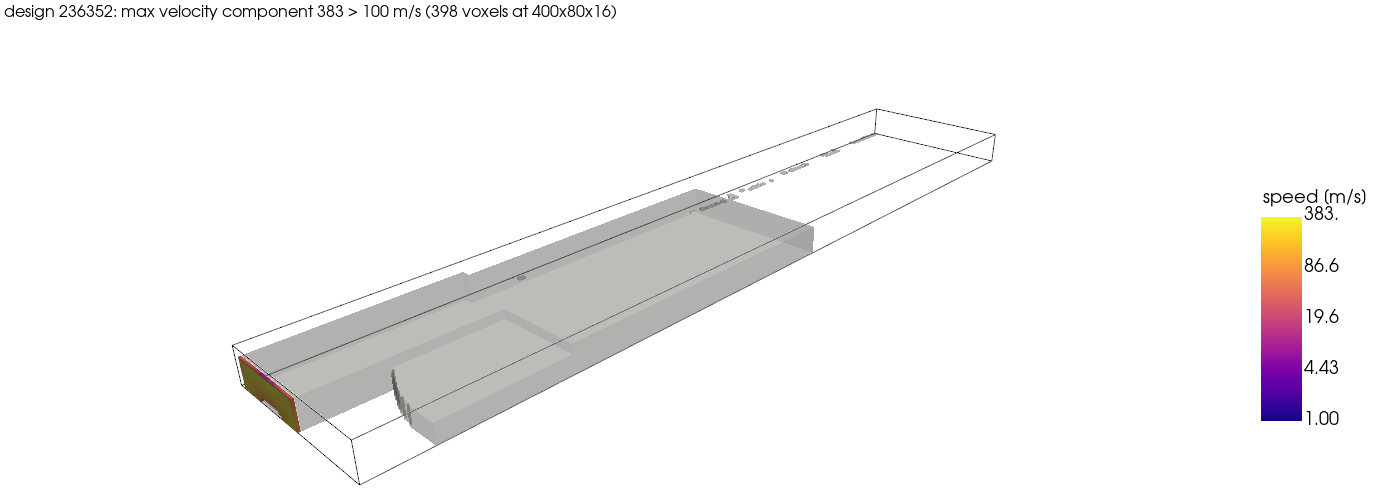

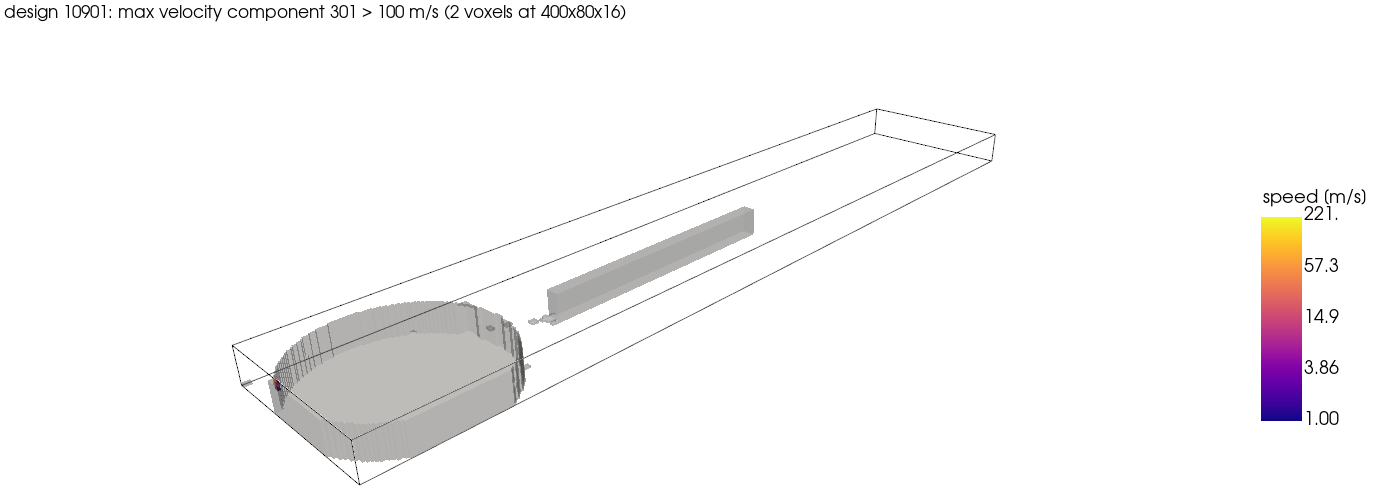

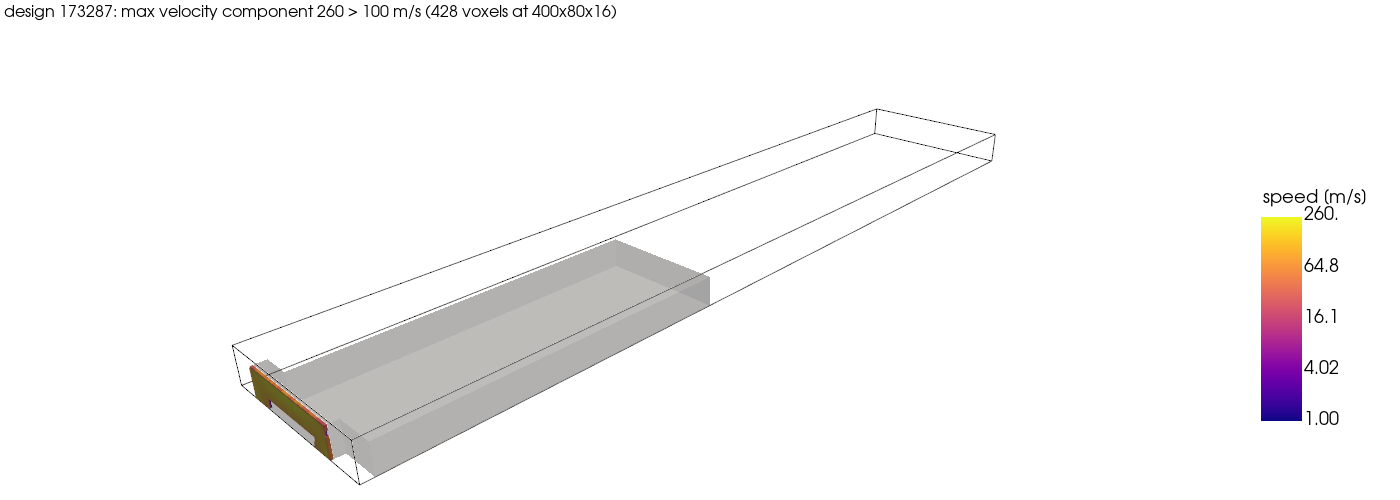

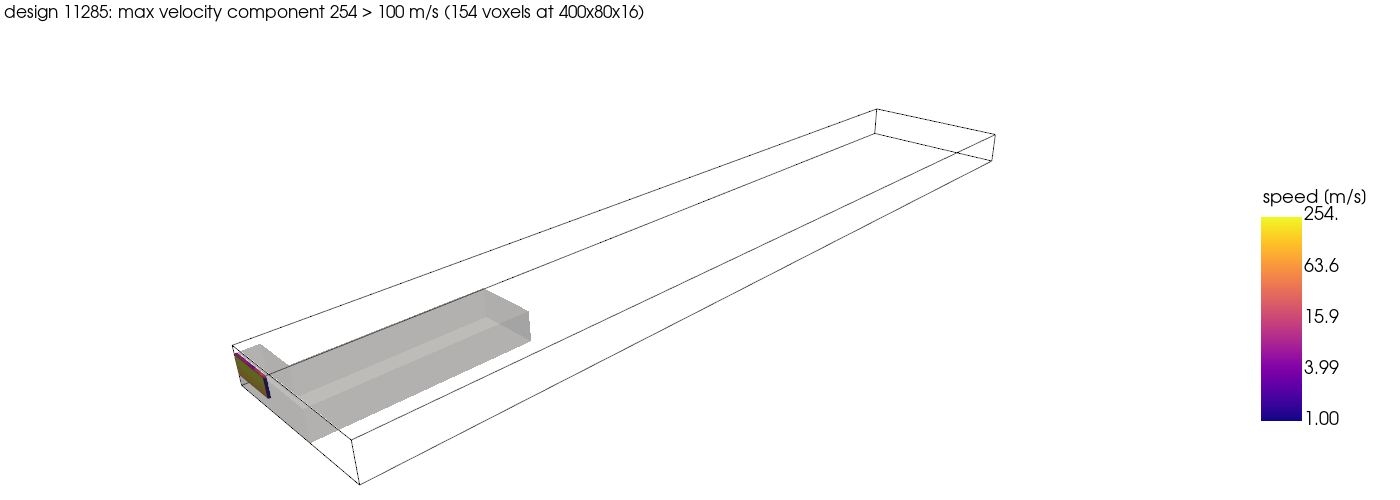

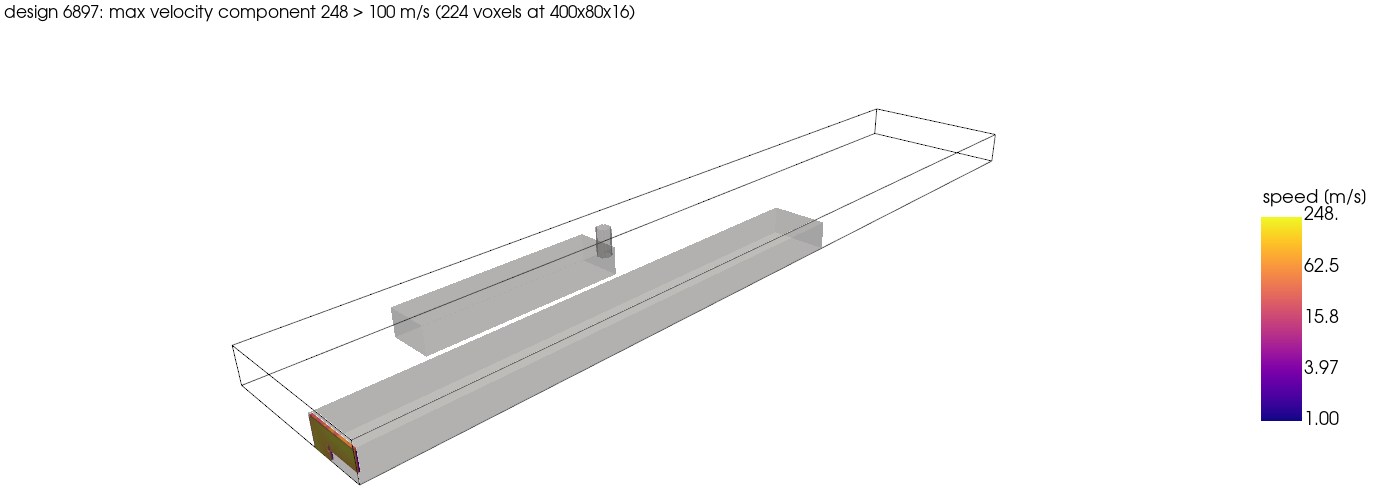

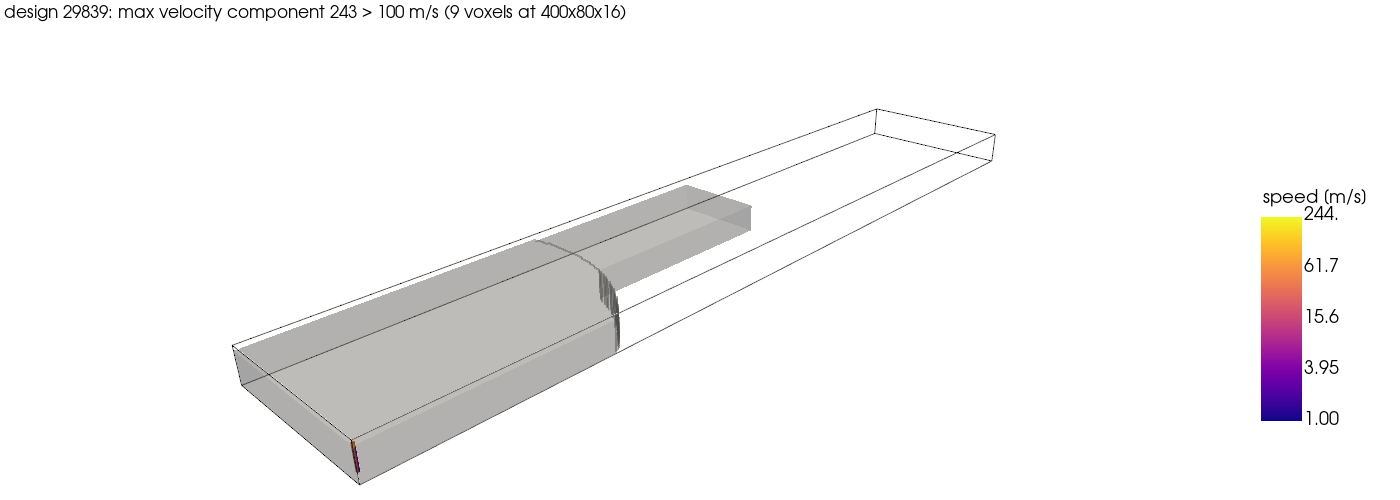

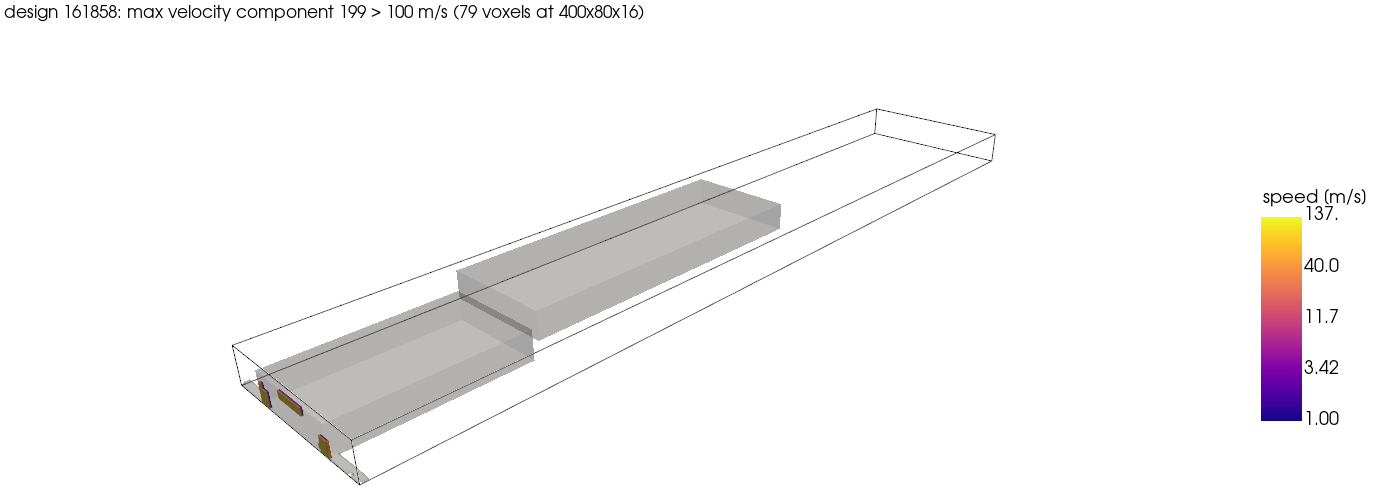

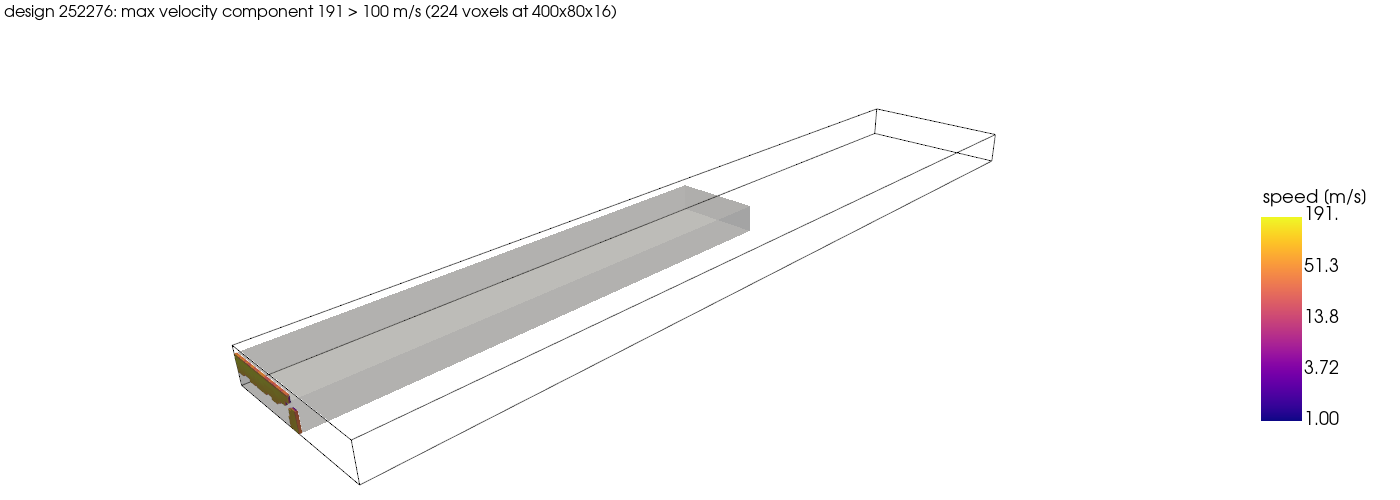

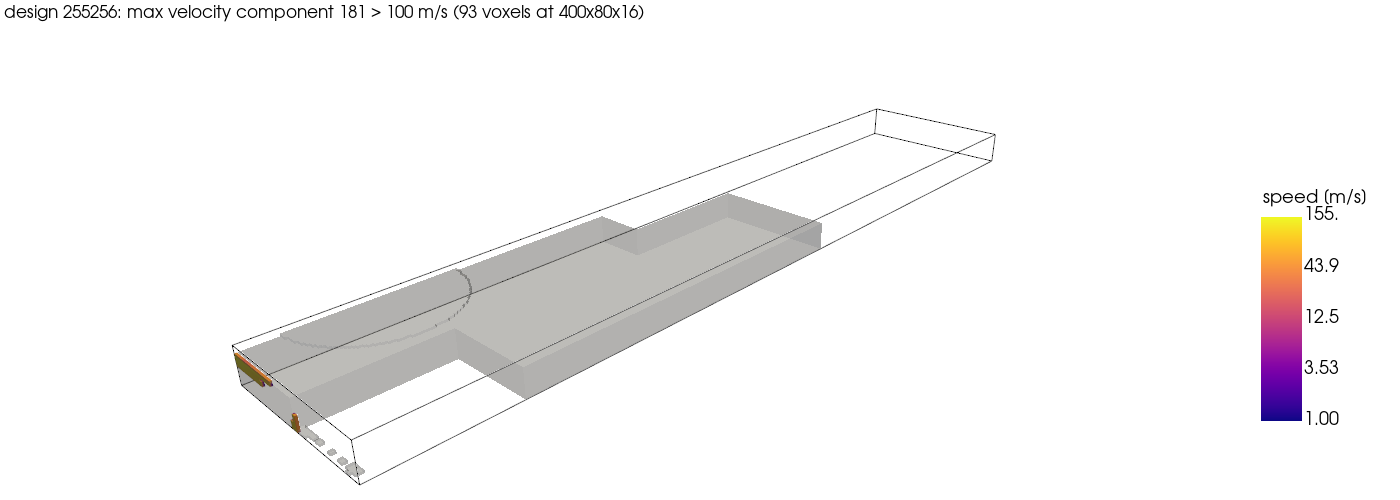

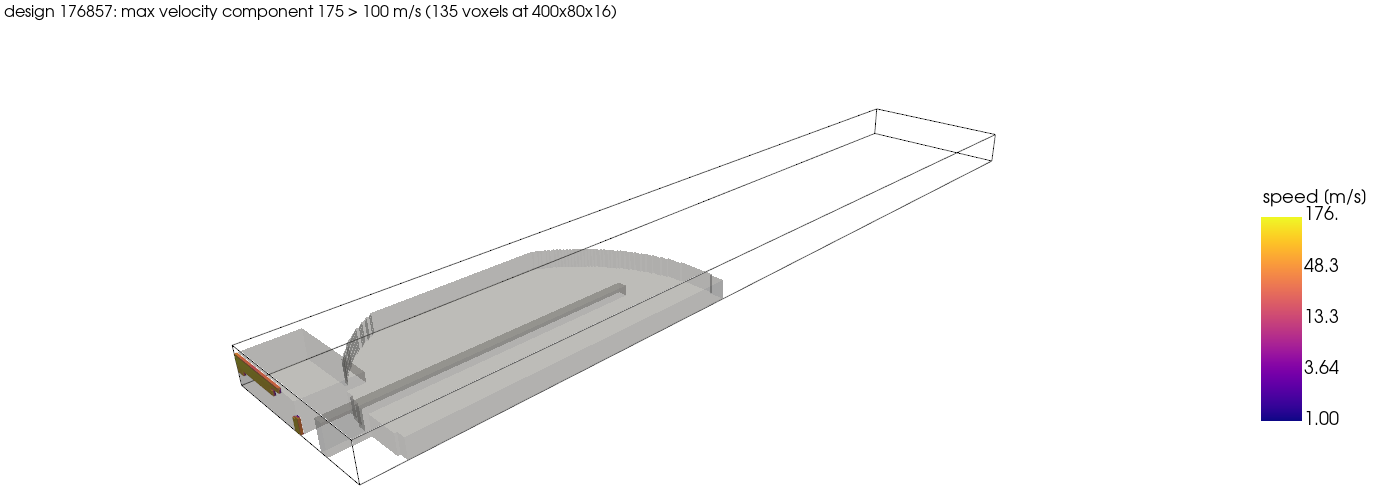

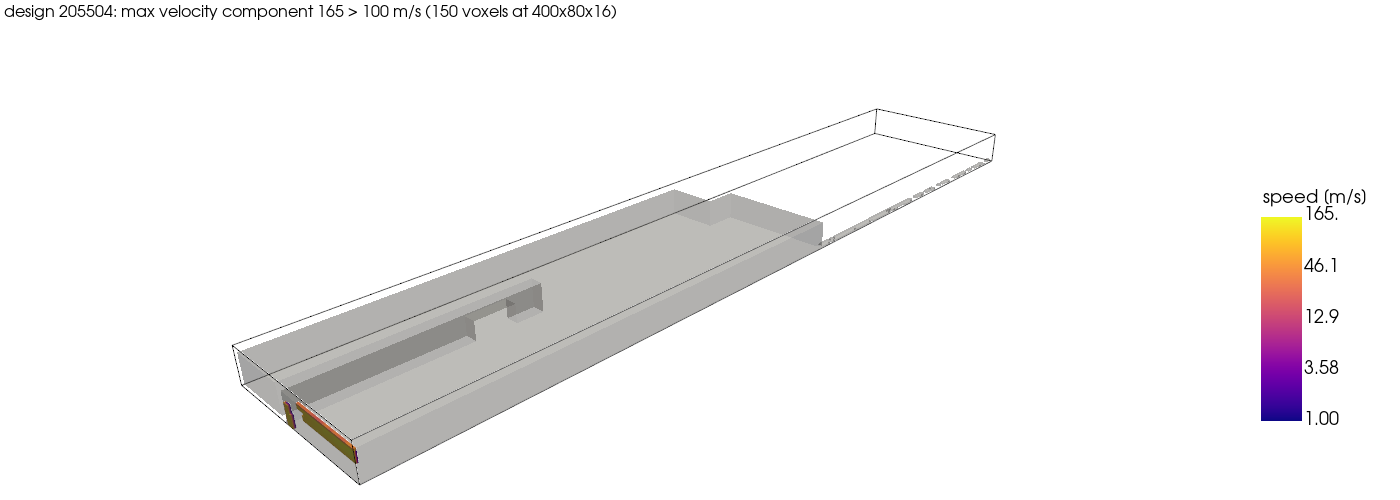

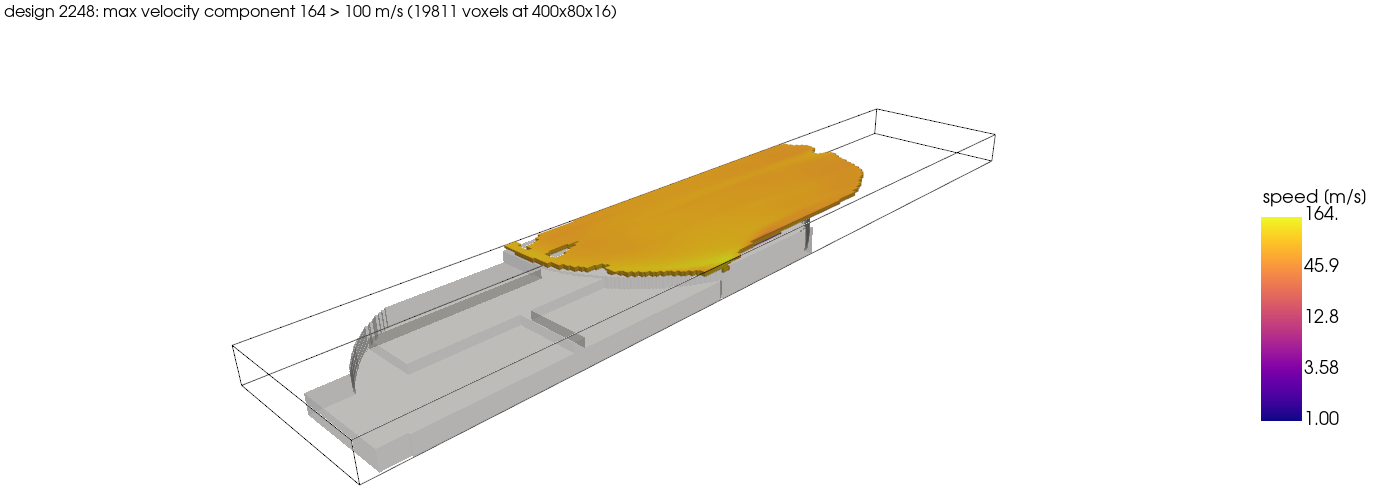

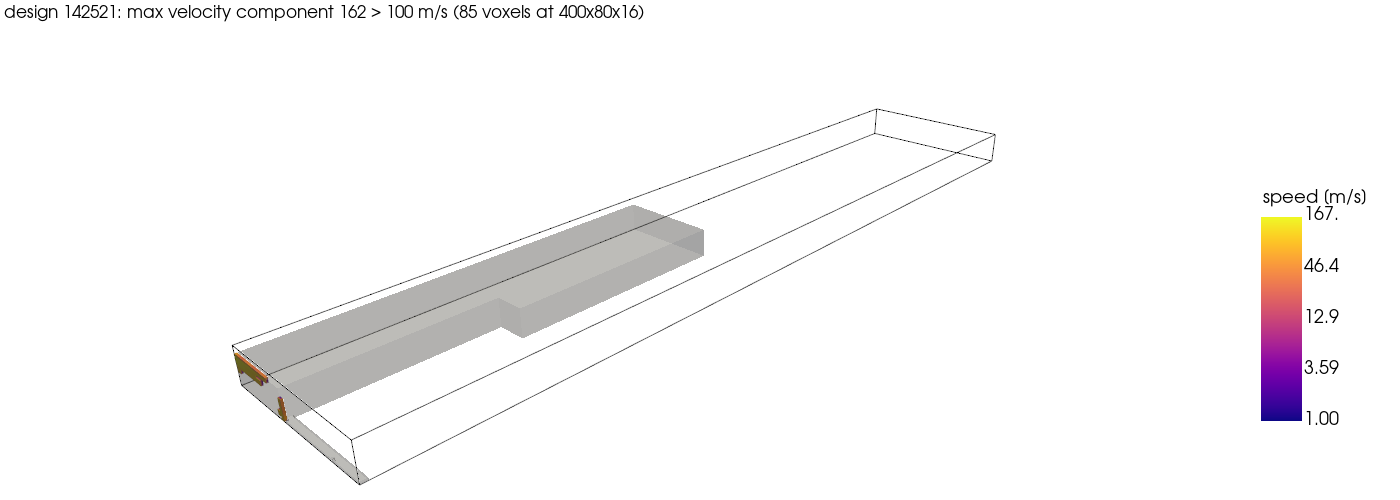

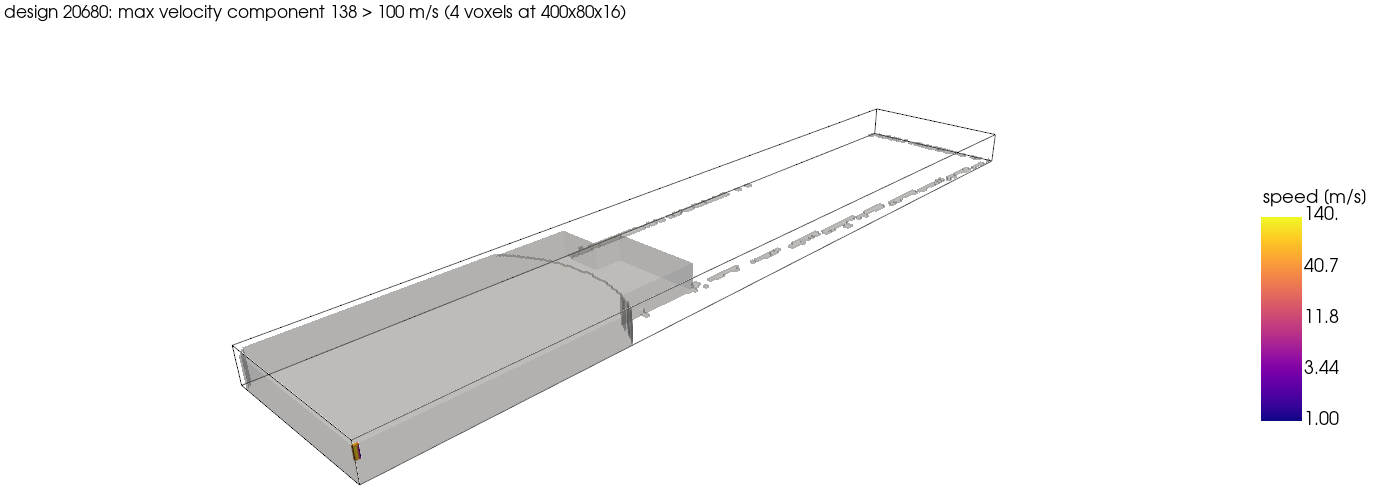

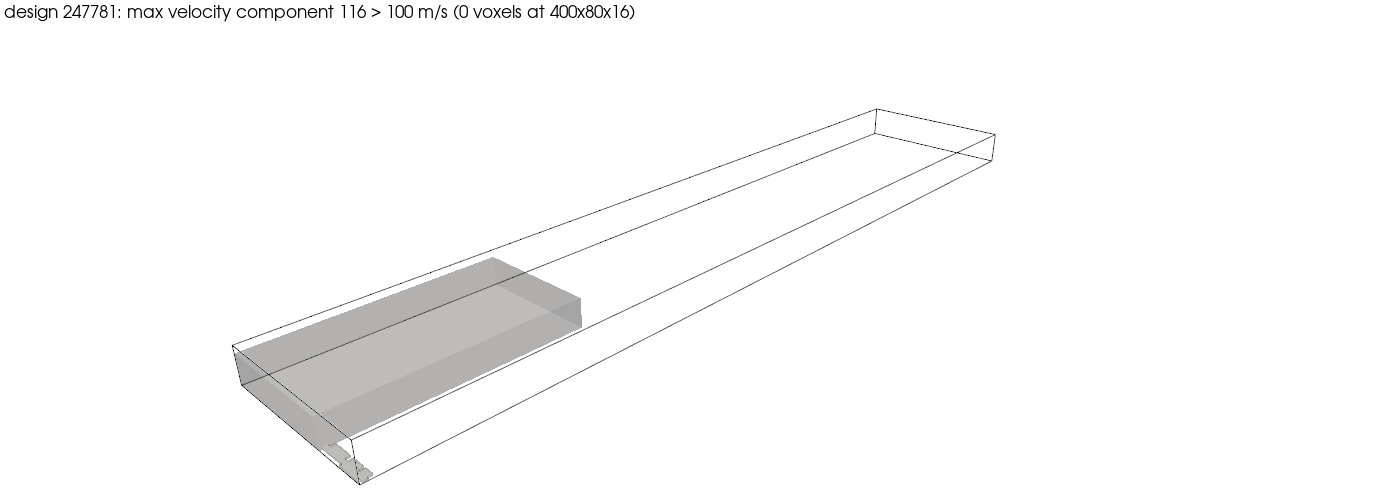

In [5]:
import pyvista as pv  # noqa: E402

JUPYTER_BACKEND = "static"


def plot_outlier_volume(design: int, reason: str) -> None:
    """Solids and rule-breaking fluid voxels of `design` in 3D."""
    flowfield = dataset[index_of_design[design]]
    fields, fluid = flowfield.fields.numpy(), flowfield.mask.numpy()
    speed = np.linalg.norm(fields[:3], axis=0)
    temperature = fields[CHANNELS.index(Channel.TEMPERATURE)]
    breaks_rule = fluid & (
        (np.abs(fields[:3]).max(axis=0) > sweep.MAX_VELOCITY)
        | (temperature < sweep.TEMPERATURE_RANGE[0])
        | (temperature > sweep.TEMPERATURE_RANGE[1])
    )
    image = pv.ImageData(dimensions=GRID.shape, spacing=GRID.spacing)
    for name, volume in (("solid", ~fluid), ("breaks_rule", breaks_rule), ("speed [m/s]", np.where(fluid, speed, 0.0))):
        image.point_data[name] = volume.astype(np.float32).ravel(order="F")
    plotter = pv.Plotter(window_size=(1400, 500))
    plotter.add_mesh(image.threshold(0.5, scalars="solid").extract_surface(), color=SOLID_COLOR, opacity=0.3)
    if breaks_rule.any():  # none when the rule only breaks at the sweep grid
        plotter.add_mesh(
            image.threshold(0.5, scalars="breaks_rule"), scalars="speed [m/s]", cmap="plasma", log_scale=True, clim=(1.0, speed[fluid].max()),
            scalar_bar_args={"vertical": True, "position_x": 0.9, "position_y": 0.15},
        )
    plotter.add_mesh(image.outline(), color="black")
    plotter.add_text(f"design {design}: {reason.replace('|V|', 'max velocity component')} ({breaks_rule.sum()} voxels at {'x'.join(map(str, GRID.shape))})", font_size=10)  # VTK fonts drop "|"
    plotter.camera_position = [(-0.12, -0.28, 0.22), (0.24, 0.05, 0.0), (0.0, 0.0, 1.0)]  # oblique, inlet in front
    plotter.show(jupyter_backend=JUPYTER_BACKEND)


for design, reason in outliers.select("design_id", "reason").iter_rows():
    plot_outlier_volume(design, reason)

## Distribution per channel

Share of all fluid voxels per bin, x in the asinh bin space of the sweep (linear within `scale` of `offset`, logarithmic beyond), labelled in physical units. Grey: all designs, blue: without flagged designs. Lines: q0.001, q0.5, q0.999 without flagged designs.

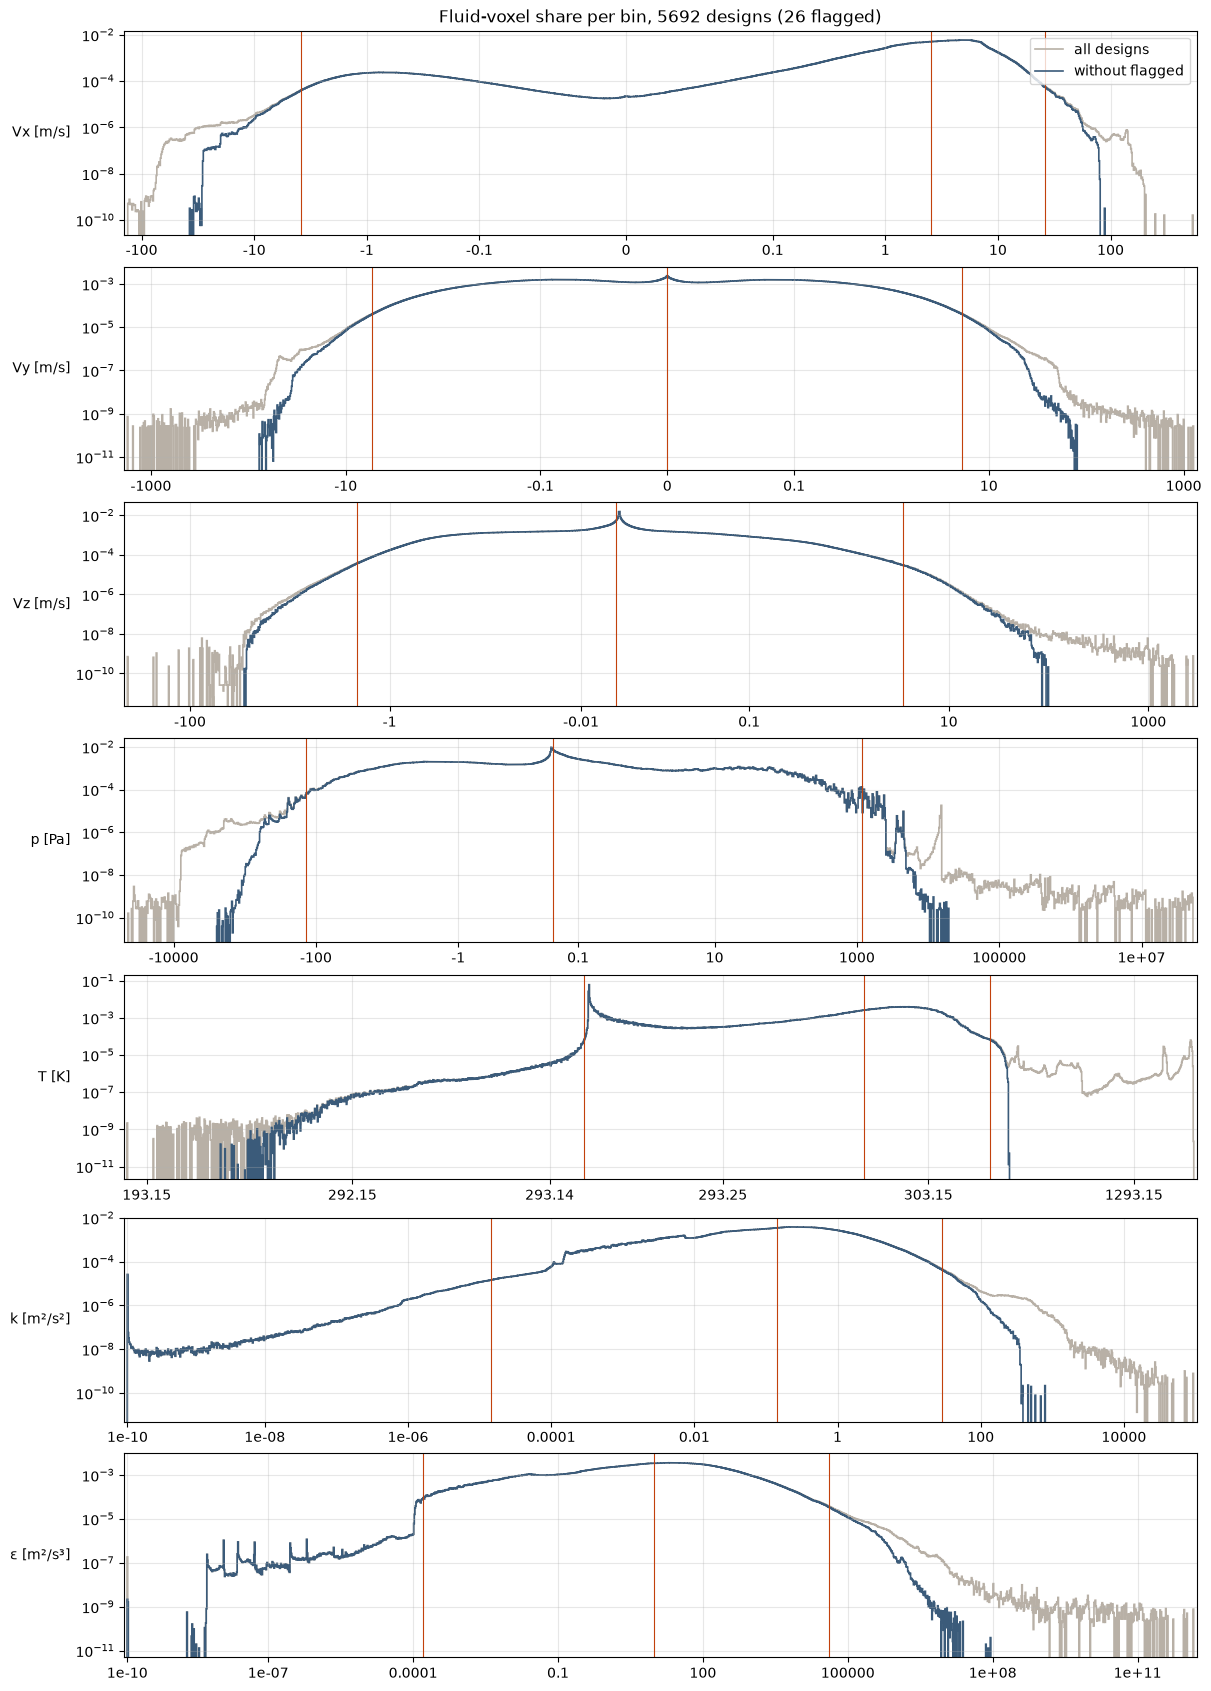

In [6]:
def physical_ticks(channel_index: int, low: float, high: float) -> tuple[np.ndarray, list[str]]:
    """Bin-space positions and labels of offset ± powers of 10 inside [low, high] bin space."""
    offset, scale, *_ = sweep.BINNING[CHANNELS[channel_index]]
    decades = np.arange(np.floor(np.log10(scale)), 15)
    values = np.concatenate([offset - 10.0 ** decades[::-1], [offset], offset + 10.0 ** decades])
    positions = np.arcsinh((values - offset) / scale)
    inside = (positions >= low) & (positions <= high)
    kept: list[int] = []
    for index in np.flatnonzero(inside):  # at most ~10 ticks, evenly spread in bin space
        if not kept or positions[index] - positions[kept[-1]] >= (high - low) / 10:
            kept.append(index)
    return positions[kept], [f"{value:.6g}" for value in values[kept]]


bin_space_edges = np.arcsinh((histograms["bin_edges"] - sweep.OFFSET.numpy()) / sweep.SCALE.numpy())  # (C, N_BINS + 1)
counts_all = counts.sum(0, dtype=np.int64)
counts_clean = counts[~is_outlier].sum(0, dtype=np.int64)
quantiles_clean = sweep.histogram_quantiles(counts_clean)  # (C, Q)

figure, axes = plt.subplots(len(CHANNELS), 1, figsize=(12, 2.4 * len(CHANNELS)), layout="constrained")
for c, (axis, channel) in enumerate(zip(axes, CHANNELS, strict=True)):
    edges = bin_space_edges[c]
    for channel_counts, color, label in ((counts_all, "#b8b0a6", "all designs"), (counts_clean, "#3b5b7a", "without flagged")):
        share = channel_counts[c] / channel_counts[c].sum()
        axis.stairs(np.where(share > 0, share, np.nan), edges, color=color, label=label, linewidth=1.2)
    occupied = np.flatnonzero(counts_all[c])
    low, high = edges[max(occupied[0] - 5, 0)], edges[min(occupied[-1] + 6, len(edges) - 1)]
    axis.set_xlim(low, high)
    for q in (1e-3, 0.5, 0.999):
        value = quantiles_clean[c, sweep.QUANTILES.index(q)]
        axis.axvline(np.arcsinh((value - sweep.OFFSET[c].item()) / sweep.SCALE[c].item()), color="#c2410c", linewidth=0.8)
    axis.set_xticks(*physical_ticks(c, low, high))
    axis.set_yscale("log")
    axis.set_ylabel(channel.value, rotation=0, ha="right", va="center")
    axis.grid(alpha=0.3)
axes[0].legend(loc="upper right")
axes[0].set_title(f"Fluid-voxel share per bin, {len(design_id)} designs ({is_outlier.sum()} flagged)")
plt.show()

## Quantiles without flagged designs

In [7]:
pl.DataFrame({"channel": [c.value for c in CHANNELS], **{f"q{q:g}": quantiles_clean[:, i] for i, q in enumerate(sweep.QUANTILES)}})

channel,q0.0001,q0.001,q0.01,q0.5,q0.99,q0.999,q0.9999
str,f64,f64,f64,f64,f64,f64,f64
"""Vx [m/s]""",-7.9761,-3.8178,-1.2823,2.5675,14.8777,26.2222,43.0563
"""Vy [m/s]""",-10.8934,-5.3641,-1.9340,-0.0001,1.9068,5.3641,11.0488
"""Vz [m/s]""",-4.8576,-2.1056,-0.7591,-0.0008,0.8383,3.5067,8.6838
"""p [Pa]""",-313.6670,-136.2458,-43.7928,0.0058,226.7955,1174.5352,2408.3168
"""T [K]""",293.1178,293.1489,293.1499,295.5386,313.9228,332.7979,343.9883
"""k [m²/s²]""",0.0000,0.0000,0.0002,0.1433,8.5168,28.4472,69.6045
"""ε [m²/s³]""",0.0000,0.0002,0.0007,9.7548,4950.0223,41699.8663,226887.3983


## Normalization

`normalization_stats.csv` of the sweep: q0.0001 and q0.9999 of the curated designs map to -1 and 1, k and ε in log10 space. Below: the curated density after normalization (share per unit of normalized value), with the share of voxels beyond ±1 and how far the curated extremes reach. Nothing is clipped.

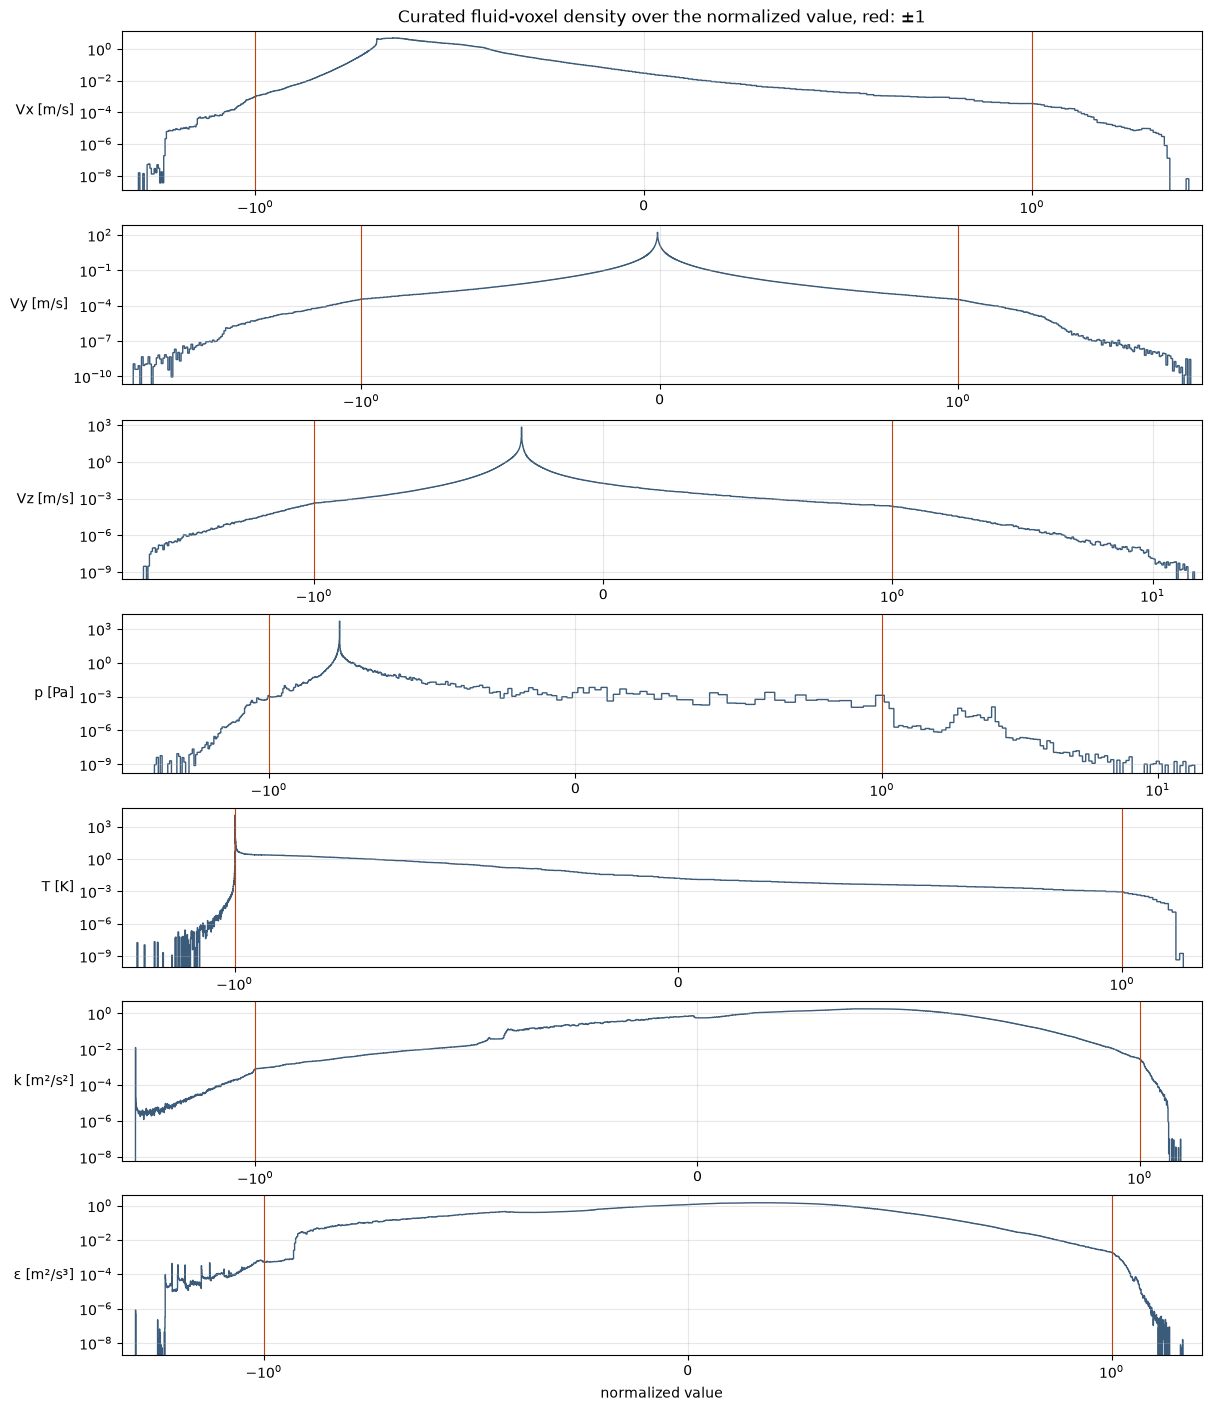

channel,transform,low,high,normalized_min,normalized_max,share_beyond_1
str,str,f64,f64,f64,f64,f64
"""Vx [m/s]""","""linear""",-7.9761,43.0563,-2.1623,2.8130,0.0002
"""Vy [m/s]""","""linear""",-10.8934,11.0488,-7.0727,7.3654,0.0002
"""Vz [m/s]""","""linear""",-4.8576,8.6838,-4.5291,14.4925,0.0002
"""p [Pa]""","""linear""",-313.6670,2408.3169,-2.6016,13.6268,0.0002
"""T [K]""","""linear""",293.1178,343.9883,-1.7562,1.4247,0.0002
"""k [m²/s²]""","""log10""",-6.0476,1.8426,-2.0019,1.2687,0.0002
"""ε [m²/s³]""","""log10""",-4.3266,5.3558,-2.1719,1.5380,0.0002


In [8]:
def normalize_values(values: np.ndarray, channel_index: int) -> np.ndarray:
    """Physical values of one channel -> normalized values under `stats`."""
    stats_channel = stats.select_channels(torch.tensor([channel_index]))
    transformed = stats_channel.transform(torch.from_numpy(values).float().view(1, -1))
    return (2 * (transformed - stats_channel.low.view(1, 1)) / (stats_channel.high - stats_channel.low).view(1, 1) - 1).flatten().numpy()


summary = []
figure, axes = plt.subplots(len(CHANNELS), 1, figsize=(12, 2.0 * len(CHANNELS)), layout="constrained")
for c, (axis, channel) in enumerate(zip(axes, CHANNELS, strict=True)):
    edges = normalize_values(histograms["bin_edges"][c], c)
    share = counts_clean[c] / counts_clean[c].sum()
    occupied = np.flatnonzero(counts_clean[c])
    edges, share = edges[occupied[0] : occupied[-1] + 2], share[occupied[0] : occupied[-1] + 1]
    density = share / np.diff(edges)  # bins differ in width after normalization
    axis.stairs(np.where(density > 0, density, np.nan), edges, color="#3b5b7a")
    for bound in (-1, 1):
        axis.axvline(bound, color="#c2410c", linewidth=0.8)
    axis.set_xscale("symlog", linthresh=1)
    axis.set_yscale("log")
    axis.set_ylabel(channel.value, rotation=0, ha="right", va="center")
    axis.grid(alpha=0.3)
    centers = 0.5 * (edges[:-1] + edges[1:])
    summary.append((channel.value, edges[0], edges[-1], share[(centers < -1) | (centers > 1)].sum()))
axes[0].set_title("Curated fluid-voxel density over the normalized value, red: ±1")
axes[-1].set_xlabel("normalized value")
plt.show()
display(pl.read_csv(PATH_RESULTS / "normalization_stats.csv").with_columns(  # noqa: F821
    pl.DataFrame(summary, schema=["channel", "normalized_min", "normalized_max", "share_beyond_1"], orient="row").drop("channel")
))